# 생태환경과 지리: 실습 4 경관진화모델링
### 전 세계 기후대와 가상유역 (120–0 ka BP)

- 계산기간: 120–0 ka BP 내 선택
- 시간간격: 1 kyr

- 모델: BIOME4–Pelletier
- 공간자료: 공통 가상유역 (20 m 격자)




In [59]:
#@title 1. Google Colab 환경 준비 (최초 한 번 실행)
import os, sys, subprocess, importlib.util
PB4_THREADS=max(1,min(int(os.cpu_count() or 1),2))
os.environ["OMP_NUM_THREADS"] = str(PB4_THREADS)
os.environ["OMP_DYNAMIC"] = "FALSE"
os.environ["OMP_WAIT_POLICY"] = "PASSIVE"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
if subprocess.run(["bash","-lc","command -v gfortran"],capture_output=True).returncode != 0:
    subprocess.check_call(["apt-get","update","-qq"])
    subprocess.check_call(["apt-get","install","-y","-qq","gfortran"])
required={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","rasterio":"rasterio","scipy":"scipy","xarray":"xarray","geopandas":"geopandas>=1.0","shapely":"shapely>=2.0","pyogrio":"pyogrio","pyproj":"pyproj","netCDF4":"netCDF4","ipywidgets":"ipywidgets","xlsxwriter":"XlsxWriter"}
missing=[spec for module,spec in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
import matplotlib.font_manager as fm
korean_fonts={"NanumGothic","Noto Sans CJK KR","Noto Sans CJK JP","Malgun Gothic"}
if not (korean_fonts & {font.name for font in fm.fontManager.ttflist}):
    subprocess.check_call(["apt-get","install","-y","-qq","fonts-nanum"])
    font_file="/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
    if os.path.isfile(font_file):
        fm.fontManager.addfont(font_file)
from pathlib import Path
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
ko_fonts=("NanumGothic","Noto Sans CJK KR","Malgun Gothic","AppleGothic")
installed={ft.name for ft in fm.fontManager.ttflist}
if not any(name in installed for name in ko_fonts):
    subprocess.check_call(["apt-get","update","-qq"])
    subprocess.check_call(["apt-get","install","-y","-qq","fonts-nanum"])
    for path in Path("/usr/share/fonts").rglob("NanumGothic*.ttf"):
        fm.fontManager.addfont(str(path))
    installed={ft.name for ft in fm.fontManager.ttflist}
font_name=next((name for name in ko_fonts if name in installed),None)
if font_name:
    plt.rcParams["font.family"]=font_name
plt.rcParams["axes.unicode_minus"]=False
print("Fortran, Python, 글꼴 준비 완료:",font_name or "기본 글꼴")
print(f"계산 자원: CPU {os.cpu_count()}개 | BIOME4 OpenMP {PB4_THREADS}스레드")

Fortran, Python, 글꼴 준비 완료: NanumGothic
계산 자원: CPU 2개 | BIOME4 OpenMP 2스레드


## 2. 입력자료


In [60]:
#@title 2. 내장 자료 복원
import base64, io, zipfile, hashlib, sys
from pathlib import Path
MODEL_DATA_COMMIT="df3949d7e94bc9a24b12a4d9a24487726554a520"
MODEL_BASE_URL=(
    "https://raw.githubusercontent.com/physical-geogrpahy-forever/"
    f"yongneup_nb/{MODEL_DATA_COMMIT}/"
    "pb4_chelsa21k/education/data/pb4studio_beyer_120ka"
)
import urllib.request, json
with urllib.request.urlopen(MODEL_BASE_URL+"/manifest.json",timeout=90) as response:
    MODEL_MANIFEST=json.loads(response.read().decode("utf-8"))
if MODEL_MANIFEST.get("format")!="pb4studio-beyer-120ka-zip-base64-v1":
    raise RuntimeError("지원하지 않는 PB4Studio Beyer 모델 형식입니다.")
_model_b64=[]
for part_name in MODEL_MANIFEST["parts"]:
    with urllib.request.urlopen(f"{MODEL_BASE_URL}/{part_name}",timeout=90) as response:
        _model_b64.append(response.read().decode("ascii").strip())
raw=base64.b64decode("".join(_model_b64))
checksum=hashlib.sha256(raw).hexdigest()
EXPECTED=MODEL_MANIFEST["sha256_zip"]
print("내장 모델 SHA256:", checksum)
if checksum != EXPECTED:
    raise RuntimeError("Beyer 120 ka PB4Studio ZIP의 SHA256이 GitHub manifest와 일치하지 않습니다.")
ROOT=Path("/content/yongneup_biome4_teaching") if Path("/content").exists() else Path.cwd()/"yongneup_biome4_teaching"
ROOT.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    archive.extractall(ROOT)
MODEL_DIR=ROOT/MODEL_MANIFEST["root_dir"]
assert (MODEL_DIR/"pb4studio"/"runner.py").is_file()
assert (MODEL_DIR/"fortran_src"/"biome4_original_4_2b2.f").is_file()
# BIOME4 native biome ID를 스냅샷과 시계열 집계에 추가
runner_path=MODEL_DIR/"pb4studio"/"runner.py"
runner_text=runner_path.read_text(encoding="utf-8")

summary_marker='        row = summarize_snapshot(int(round(igrid.resolution_m)), float(ka), z, h, veg_code, npp, eemt, igrid.land)\n'
if '"biome4_full_id_counts"' not in runner_text:
    if runner_text.count(summary_marker)!=1:
        raise RuntimeError("runner.py의 BIOME4 집계 위치를 찾지 못했습니다.")
    summary_insert=summary_marker+'''        native_biome=np.asarray(
            veg.get("biome4_full_id_node",np.full(igrid.shape,np.nan)),
            dtype="float32"
        )
        native_land=native_biome[igrid.land]
        native_valid=native_land[np.isfinite(native_land)]
        if native_valid.size:
            native_ids,native_counts=np.unique(native_valid.astype("int16"),return_counts=True)
            row["dominant_biome4_id"]=int(native_ids[np.argmax(native_counts)])
            row["biome4_full_id_counts"]=";".join(
                f"{int(k)}:{int(v)}" for k,v in zip(native_ids,native_counts)
            )
        else:
            row["dominant_biome4_id"]=-1
            row["biome4_full_id_counts"]=""
'''
    runner_text=runner_text.replace(summary_marker,summary_insert,1)

# Beyer 120 ka 원본 runner의 summary_timeseries에 BIOME4/PFT 진단값 추가
diagnostic_marker='        row.update({\n'
if '"mean_agb_proxy_kg_m2"' not in runner_text:
    if runner_text.count(diagnostic_marker)!=1:
        raise RuntimeError("runner.py의 요약 진단 삽입 위치를 찾지 못했습니다.")
    diagnostic_insert='''        def _pb4_grid(field_name,fill=np.nan):
            arr=np.asarray(
                veg.get(field_name,np.full(igrid.shape,fill)),
                dtype="float64"
            )
            if arr.shape!=igrid.land.shape:
                if arr.size==igrid.land.size:
                    arr=arr.reshape(igrid.land.shape)
                else:
                    return np.full(igrid.land.shape,fill,dtype="float64")
            return arr

        def _pb4_land_mean(field_name):
            arr=_pb4_grid(field_name,np.nan)
            vals=arr[igrid.land & np.isfinite(arr)]
            return float(np.mean(vals)) if vals.size else np.nan

        row["mean_lai"]=_pb4_land_mean("lai_node")
        row["mean_aet_mm_yr"]=_pb4_land_mean("aet_node")
        row["mean_runoff_mm_yr"]=_pb4_land_mean("runoff_node")
        _agb_vals=np.asarray(agb,dtype="float64")
        if _agb_vals.shape!=igrid.land.shape and _agb_vals.size==igrid.land.size:
            _agb_vals=_agb_vals.reshape(igrid.land.shape)
        _agb_valid=_agb_vals[igrid.land & np.isfinite(_agb_vals)]
        row["mean_agb_proxy_kg_m2"]=float(np.mean(_agb_valid)) if _agb_valid.size else np.nan

        _pft_npp_stack=[]
        _pft_pass_stack=[]
        for _pid in range(1,14):
            _prefix=f"pft{_pid:02d}_"
            _npp_grid=_pb4_grid(_prefix+"mod_npp_node",np.nan)
            _lai_grid=_pb4_grid(_prefix+"mod_lai_node",np.nan)
            _pass=_pb4_grid(_prefix+"constraint_pass_node",0.0)

            _npp_vals=_npp_grid[igrid.land & np.isfinite(_npp_grid)]
            _lai_vals=_lai_grid[igrid.land & np.isfinite(_lai_grid)]
            _valid=igrid.land & np.isfinite(_pass)

            row[_prefix+"npp_mean"]=float(np.mean(_npp_vals)) if _npp_vals.size else np.nan
            row[_prefix+"lai_mean"]=float(np.mean(_lai_vals)) if _lai_vals.size else np.nan
            row[_prefix+"constraint_pass_fraction"]=(
                float(np.mean(_pass[_valid]>0)) if np.any(_valid) else np.nan
            )
            _pft_npp_stack.append(_npp_grid)
            _pft_pass_stack.append(_pass>0)

        _opt=_pb4_grid("optpft_node",0.0)
        _opt_codes=np.rint(_opt).astype(int)
        _opt_land=_opt_codes[igrid.land & np.isfinite(_opt)]
        _opt_nonzero=int(np.sum((_opt_land>=1)&(_opt_land<=13)))

        # 일부 원본 BIOME4 실행에서 optPFT 코드가 0만 반환될 수 있다.
        # 이 경우에는 제약을 통과한 PFT 중 잠재 NPP 최대값을 '진단용 우점 PFT'로 별도 계산한다.
        if _opt_nonzero>0:
            _selected=_opt_codes
            _selection_source="BIOME4 optPFT"
        else:
            _npp_cube=np.stack(_pft_npp_stack,axis=0)
            _pass_cube=np.stack(_pft_pass_stack,axis=0)
            _score=np.where(
                _pass_cube & np.isfinite(_npp_cube),
                _npp_cube,
                -np.inf
            )
            _best=np.argmax(_score,axis=0)+1
            _best_score=np.max(_score,axis=0)
            _selected=np.where(
                igrid.land & np.isfinite(_best_score) & (_best_score>0),
                _best,
                0
            ).astype(int)
            _selection_source="잠재 NPP 최대값(진단용)"

        row["pft_selection_source"]=_selection_source
        for _pid in range(0,14):
            row[f"selected_pft{_pid:02d}_count"]=int(
                np.sum(_selected[igrid.land]==_pid)
            )
'''
    runner_text=runner_text.replace(diagnostic_marker,diagnostic_insert+diagnostic_marker,1)

snapshot_marker='            if "lai_node" in veg:\n'
if 'snapshot_fields["biome4_full_id"]' not in runner_text:
    if runner_text.count(snapshot_marker)<1:
        raise RuntimeError("runner.py의 스냅샷 출력 위치를 찾지 못했습니다.")
    runner_text=runner_text.replace(
        snapshot_marker,
        '            snapshot_fields["biome4_full_id"] = native_biome\n'+snapshot_marker,
        1
    )

# 패치한 모델을 새로 불러옴
compile(runner_text,str(runner_path),"exec")
assert 'snapshot_fields["biome4_full_id"]' in runner_text
assert '"biome4_full_id_counts"' in runner_text
runner_path.write_text(runner_text,encoding="utf-8")
# 같은 Colab 런타임에서 과거 pb4studio 모듈이 캐시되는 문제 방지
for module_name in list(sys.modules):
    if module_name=="pb4studio" or module_name.startswith("pb4studio."):
        del sys.modules[module_name]
if str(MODEL_DIR) in sys.path:
    sys.path.remove(str(MODEL_DIR))
sys.path.insert(0,str(MODEL_DIR))
from pb4studio.config import RunConfig, RunMode, InputPaths, TimeConfig, ScienceConfig
from pb4studio import runner
# 120 ka Beyer 버전인지 즉시 확인
_time_contract=TimeConfig(
    start_ka=120.0,end_ka=0.0,interval_kyr=1.0,
    snapshot_ka=(120.0,90.0,60.0,30.0,0.0)
)
assert _time_contract.snapshot_times_ka()[0]==120.0
assert _time_contract.snapshot_times_ka()[-1]==0.0
print("PB4Studio Beyer 시간범위 확인: 120–0 ka BP")
# 전 세계 유명 도시·지역 Beyer 기후는 원래 수치를 그대로 사용한다.
# 원본 PB4Studio의 용늪 전용 고도감률을 적용하지 않도록 학생용 long CSV를 직접 읽는다.
_original_global_load_climate=runner.load_climate

def _load_global_representative_climate(path,*args,**kwargs):
    climate_path=Path(path)
    if climate_path.suffix.lower()==".csv" and climate_path.is_file():
        probe=pd.read_csv(climate_path)
        required={
            "ka_bp","month","temp_C","precip_mm","cloud_pct","tmin_C"
        }
        if required.issubset(probe.columns):
            df=probe.copy()
            df["ka_bp"]=pd.to_numeric(df["ka_bp"],errors="raise").astype(float)
            df["month"]=pd.to_numeric(df["month"],errors="raise").astype(int)
            for col in ("temp_C","precip_mm","cloud_pct","tmin_C"):
                df[col]=pd.to_numeric(df[col],errors="raise").astype(float)

            if not df["month"].between(1,12).all():
                raise ValueError("Beyer 대표지점 기후의 month는 1..12여야 합니다.")
            monthly_counts=df.groupby("ka_bp")["month"].nunique()
            if not monthly_counts.eq(12).all():
                bad=monthly_counts.loc[~monthly_counts.eq(12)].to_dict()
                raise ValueError(
                    f"Beyer 대표지점 기후는 각 시점마다 12개월이 필요합니다: {bad}"
                )
            if df[["ka_bp","month"]].duplicated().any():
                raise ValueError("Beyer 대표지점 기후에 중복 ka_bp-month 행이 있습니다.")
            if not np.isfinite(
                df[["ka_bp","temp_C","precip_mm","cloud_pct","tmin_C"]].to_numpy(float)
            ).all():
                raise ValueError("Beyer 대표지점 기후에 비정상 값이 있습니다.")

            df["precip_mm"]=df["precip_mm"].clip(lower=0.0)
            df["cloud_pct"]=df["cloud_pct"].clip(lower=0.0,upper=100.0)
            df["lapse_rate_C_per_m"]=0.0
            df["tmin_lapse_rate_C_per_m"]=0.0
            df["reference_elevation_m"]=0.0
            return df.sort_values(["ka_bp","month"]).reset_index(drop=True)

    # 학생용 전 세계 기후표가 아닌 입력은 원래 PB4Studio 로더 사용
    df=_original_global_load_climate(path,*args,**kwargs).copy()
    for col in ("lapse_rate_C_per_m","tmin_lapse_rate_C_per_m"):
        df[col]=0.0
    df["reference_elevation_m"]=0.0
    return df

runner.load_climate=_load_global_representative_climate
import inspect
assert Path(runner.__file__).resolve()==runner_path.resolve()
runner_source=inspect.getsource(runner.run_single_case)
assert 'snapshot_fields["biome4_full_id"]' in runner_source
assert '"biome4_full_id_counts"' in runner_source
print("BIOME4 native biome GeoTIFF/집계 출력 확인 — GLOBAL120 FIX 2026-11-06")



내장 모델 SHA256: 17c755af300aa25369692addaa5ffc1b0c0c66f48d11401bc5ab31795f8e5529
PB4Studio Beyer 시간범위 확인: 120–0 ka BP
BIOME4 native biome GeoTIFF/집계 출력 확인 — GLOBAL120 FIX 2026-11-06


0 ka 기후형 20개 | 유명 도시·지역 52개 | 시기 120–0 ka BP

쾨펜 기후형 설명
국문명은 국내 지리학·기후학에서 통용되는 기후명을 사용하고, a/b/c/d·h/k 차이는 '세부형'에 구분했습니다.


,쾨펜 코드,영문명,국문명,세부형,설명
0,Af,Tropical rainforest,열대 우림 기후,건기 없음,연중 고온다습하며 뚜렷한 건기가 없다.
1,Am,Tropical monsoon,열대 몬순 기후,짧은 건기,연중 고온이며 짧은 건기와 뚜렷한 우기가 나타난다.
2,Aw,Tropical savannah,사바나 기후,겨울 건조,연중 고온이며 겨울철 건기가 뚜렷한 사바나 기후이다.
3,BSh,Arid steppe hot,스텝 기후,고온형 (h),스텝 기후 가운데 연평균 기온이 높은 고온형이다.
4,BSk,Arid steppe cold,스텝 기후,한랭형 (k),스텝 기후 가운데 연평균 기온이 낮은 한랭형이다.
5,BWh,Arid desert hot,사막 기후,고온형 (h),사막 기후 가운데 연평균 기온이 높은 고온형이다.
6,BWk,Arid desert cold,사막 기후,한랭형 (k),사막 기후 가운데 연평균 기온이 낮은 한랭형이다.
7,Cfa,"Temperate no dry season, hot summer",온난 습윤 기후,고온 여름형 (a),건기가 뚜렷하지 않고 여름이 더운 온난 습윤 기후이다.
8,Cfb,"Temperate no dry season, warm summer",서안 해양성 기후,온난 여름형 (b),연중 강수가 비교적 고르게 나타나며 여름이 온난한 서안 해양성 기후이다.
9,Csa,"Temperate dry summer, hot summer",지중해성 기후,고온 여름형 (a),여름이 덥고 건조하며 겨울은 온화하고 상대적으로 습하다.



0 ka BP 유명 도시·지역별 월별 기온·강수량


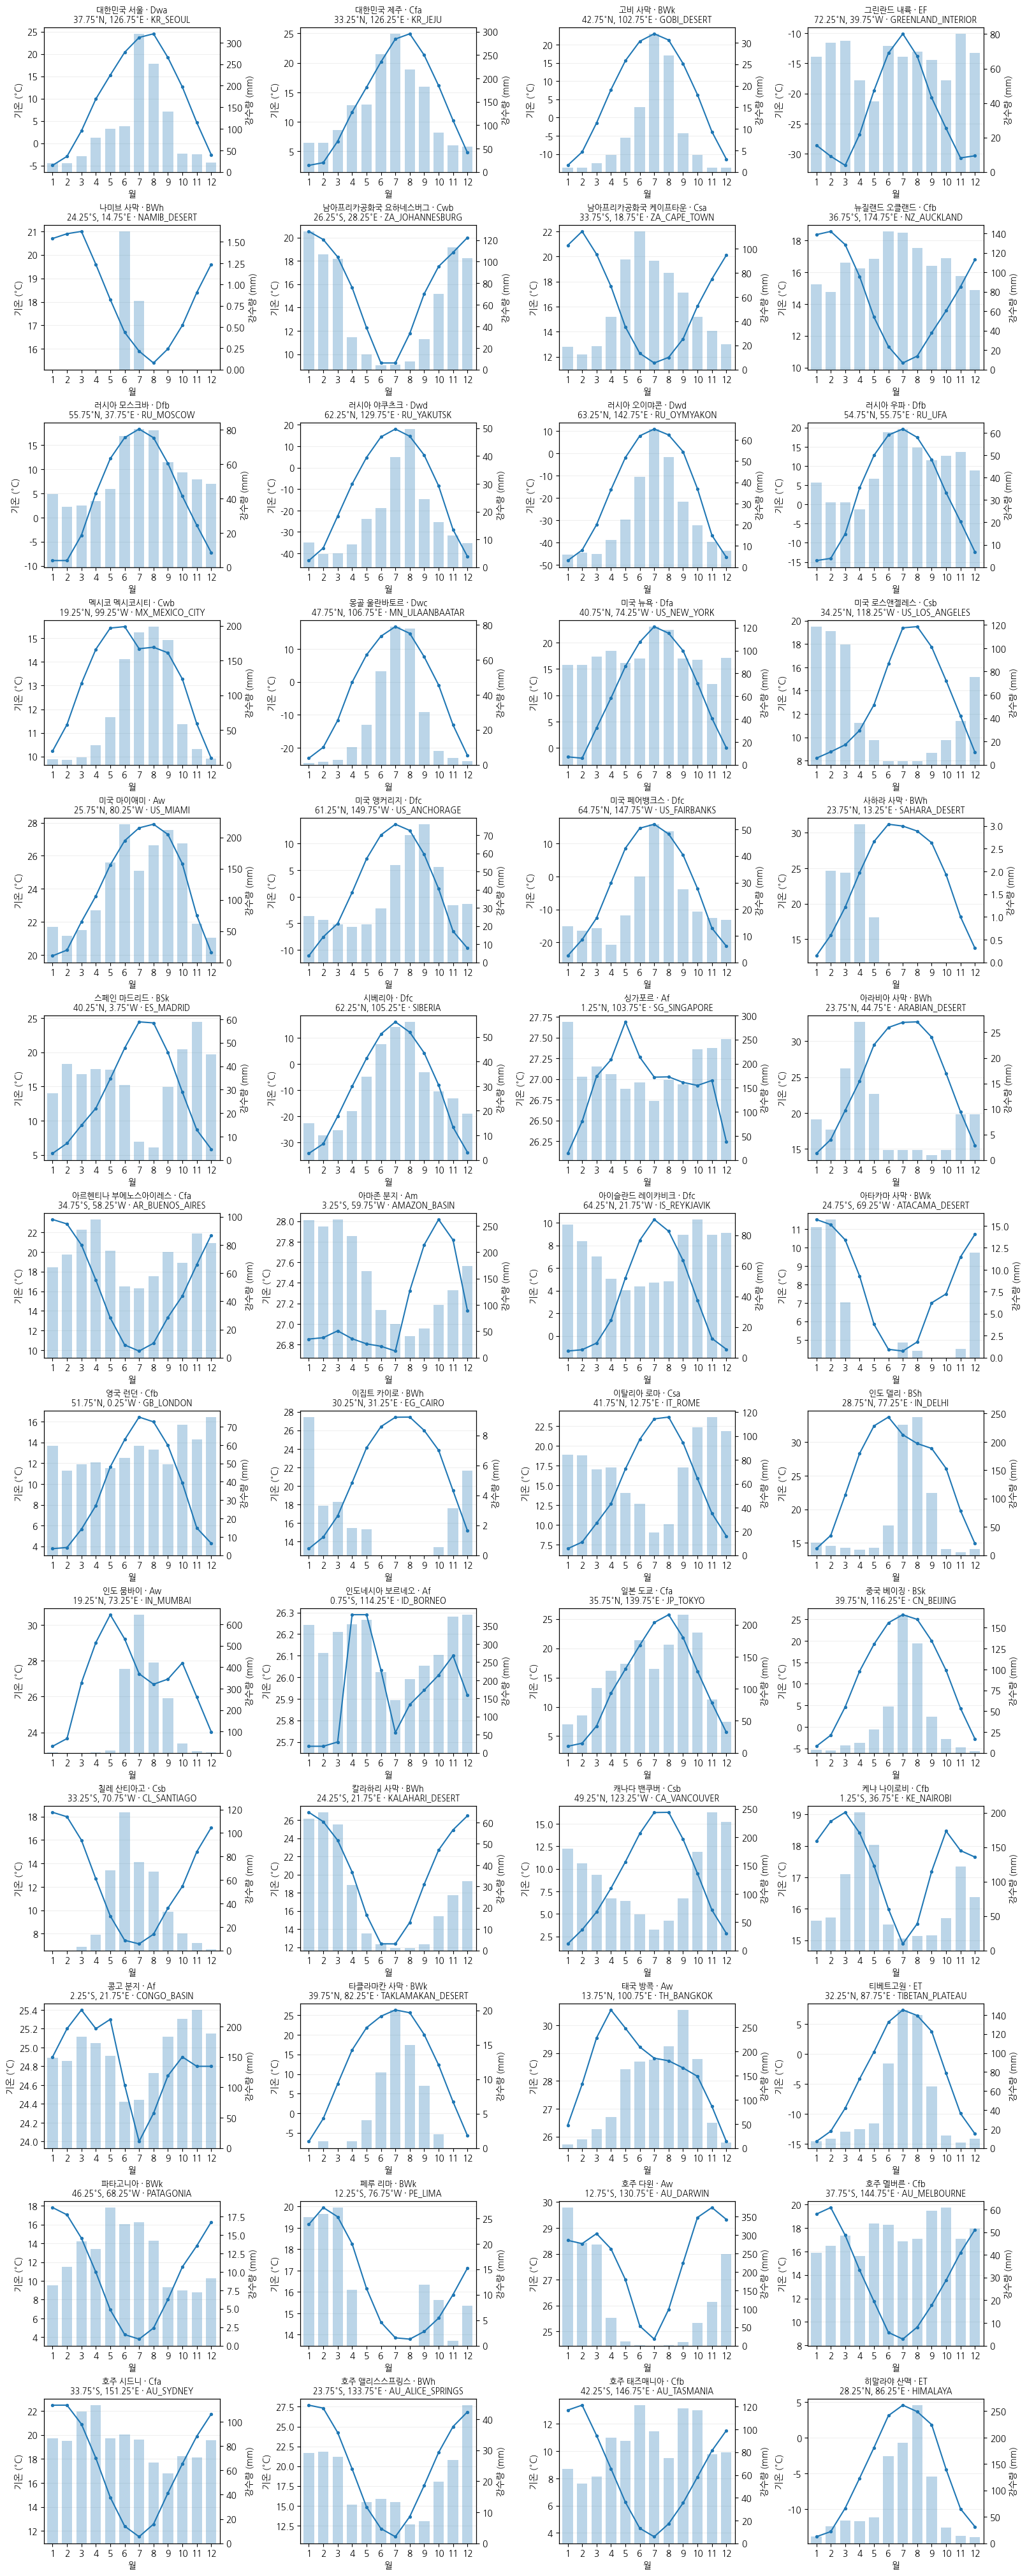


유명 도시·지리지역 대표 지점


,대표지점 ID,지명,유형,쾨펜 코드,기후형,위도,경도,기준좌표와 거리 (km),기후형 안정성 (%)
0,KR_SEOUL,대한민국 서울,city,Dwa,"Cold dry winter, hot summer",37.75,126.75,28.621145,100.0
1,KR_JEJU,대한민국 제주,city,Cfa,"Temperate no dry season, hot summer",33.25,126.25,38.106633,100.0
2,GOBI_DESERT,고비 사막,region,BWk,Arid desert cold,42.75,102.75,34.513051,100.0
3,GREENLAND_INTERIOR,그린란드 내륙,region,EF,Polar frost,72.25,-39.75,29.078741,100.0
4,NAMIB_DESERT,나미브 사막,region,BWh,Arid desert hot,-24.25,14.75,37.635659,75.0
5,ZA_JOHANNESBURG,남아프리카공화국 요하네스버그,city,Cwb,"Temperate dry winter, warm summer",-26.25,28.25,20.853058,100.0
6,ZA_CAPE_TOWN,남아프리카공화국 케이프타운,city,Csa,"Temperate dry summer, hot summer",-33.75,18.75,35.836557,75.0
7,NZ_AUCKLAND,뉴질랜드 오클랜드,city,Cfb,"Temperate no dry season, warm summer",-36.75,174.75,11.016548,100.0
8,RU_MOSCOW,러시아 모스크바,city,Dfb,"Cold no dry season, warm summer",55.75,37.75,8.328906,100.0
9,RU_YAKUTSK,러시아 야쿠츠크,city,Dwd,"Cold dry winter, very cold winter",62.25,129.75,23.868472,75.0


In [61]:
#@title 2A. 기후자료 불러오기
import io, lzma, hashlib, urllib.request, base64, json
import pandas as pd
import numpy as np

CLIMATE_DATA_COMMIT="742398db789c2be4e96368532994a3ba77c11e57"
CLIMATE_BASE_URL=(
    "https://raw.githubusercontent.com/physical-geogrpahy-forever/"
    f"yongneup_nb/{CLIMATE_DATA_COMMIT}/"
    "pb4_chelsa21k/education/data/beyer_landmark_global_120ka"
)

with urllib.request.urlopen(CLIMATE_BASE_URL+"/manifest.json",timeout=90) as response:
    climate_manifest=json.loads(response.read().decode("utf-8"))

if climate_manifest.get("format")!="pb4-beyer-landmark-xor-f32-lzma-base64-v1":
    raise RuntimeError("지원하지 않는 기후자료 형식입니다.")

CLIMATE_CACHE=ROOT/"beyer_landmark_global_120ka.xor.xz"
compressed=None
if CLIMATE_CACHE.is_file():
    cached=CLIMATE_CACHE.read_bytes()
    if hashlib.sha256(cached).hexdigest()==climate_manifest["sha256_lzma"]:
        compressed=cached
    else:
        CLIMATE_CACHE.unlink()

if compressed is None:
    encoded_parts=[]
    for part_name in climate_manifest["parts"]:
        with urllib.request.urlopen(
            f"{CLIMATE_BASE_URL}/{part_name}",timeout=90
        ) as response:
            encoded_parts.append(response.read().decode("ascii").strip())
    compressed=base64.b64decode("".join(encoded_parts))
    if hashlib.sha256(compressed).hexdigest()!=climate_manifest["sha256_lzma"]:
        raise RuntimeError("GitHub 기후자료 SHA256 불일치")
    CLIMATE_CACHE.write_bytes(compressed)

raw_xor=lzma.decompress(compressed)
if hashlib.sha256(raw_xor).hexdigest()!=climate_manifest["sha256_raw_xor"]:
    raise RuntimeError("기후자료 압축 해제 후 SHA256 불일치")

shape=tuple(int(x) for x in climate_manifest["shape"])
xor_values=np.frombuffer(raw_xor,dtype="<u4").reshape(shape)
value_bits=np.bitwise_xor.accumulate(xor_values,axis=-1)
climate_values=value_bits.view("<f4")

variable_names=list(climate_manifest["variable_names"])
climate_ages=np.asarray(climate_manifest["ka_bp"],dtype=int)
climate_months=np.asarray(climate_manifest["months"],dtype=int)
representatives=list(climate_manifest["representatives"])

if climate_values.shape!=(
    len(representatives),len(variable_names),
    len(climate_months),len(climate_ages)
):
    raise RuntimeError("기후자료 배열 크기와 manifest가 일치하지 않습니다.")

records=[]
for ri,meta in enumerate(representatives):
    for ai,age in enumerate(climate_ages):
        for mi,month in enumerate(climate_months):
            rec=dict(meta)
            rec["ka_bp"]=int(age)
            rec["month"]=int(month)
            for vi,var_name in enumerate(variable_names):
                rec[var_name]=float(climate_values[ri,vi,mi,ai])
            records.append(rec)

CLIMATE_MASTER=pd.DataFrame.from_records(records)
required_columns={
    "representative_id","landmark_name_ko","landmark_type",
    "koppen_reference_0ka","koppen_name",
    "source_grid_lon","source_grid_lat",
    "distance_from_anchor_km","robustness_pct",
    "ka_bp","month",
    "temp_C","precip_mm","cloud_pct","relative_humidity","wind_speed"
}
missing=required_columns-set(CLIMATE_MASTER.columns)
if missing:
    raise ValueError(f"기후자료 열 누락: {sorted(missing)}")

CLIMATE_MASTER["ka_bp"]=CLIMATE_MASTER["ka_bp"].astype(int)
CLIMATE_MASTER["month"]=CLIMATE_MASTER["month"].astype(int)

climate_places=(
    CLIMATE_MASTER.sort_values(["representative_id","ka_bp"])
    .drop_duplicates("representative_id")
    [[
        "representative_id","landmark_name_ko","landmark_type",
        "koppen_reference_0ka","koppen_name",
        "source_grid_lon","source_grid_lat",
        "distance_from_anchor_km","robustness_pct"
    ]]
    .reset_index(drop=True)
)

# 대한민국을 먼저, 이후 지명을 가나다/문자열 순으로 표시
climate_places["_display_priority"]=np.select(
    [
        climate_places.representative_id.eq("KR_SEOUL"),
        climate_places.representative_id.eq("KR_JEJU")
    ],
    [0,1],
    default=2
)
climate_places=(
    climate_places
    .sort_values(["_display_priority","landmark_name_ko","representative_id"])
    .drop(columns="_display_priority")
    .reset_index(drop=True)
)

def _coord_label(lat,lon):
    ns="N" if float(lat)>=0 else "S"
    ew="E" if float(lon)>=0 else "W"
    return f"{abs(float(lat)):.2f}°{ns}, {abs(float(lon)):.2f}°{ew}"

climate_places["region_name"]=climate_places["landmark_name_ko"]
climate_places["place_label"]=[
    f"{row.landmark_name_ko} ({_coord_label(row.source_grid_lat,row.source_grid_lon)}) · {row.representative_id}"
    for row in climate_places.itertuples(index=False)
]

# 쾨펜 기후형 설명
_KOPPEN_KO={
    "Af":"열대 우림 기후",
    "Am":"열대 몬순 기후",
    "Aw":"사바나 기후",
    "BWh":"사막 기후",
    "BWk":"사막 기후",
    "BSh":"스텝 기후",
    "BSk":"스텝 기후",
    "Csa":"지중해성 기후",
    "Csb":"지중해성 기후",
    "Csc":"지중해성 기후",
    "Cwa":"온대 겨울 건조 기후",
    "Cwb":"온대 겨울 건조 기후",
    "Cwc":"온대 겨울 건조 기후",
    "Cfa":"온난 습윤 기후",
    "Cfb":"서안 해양성 기후",
    "Cfc":"아극 해양성 기후",
    "Dsa":"고지 지중해성 기후",
    "Dsb":"고지 지중해성 기후",
    "Dsc":"고지 지중해성 기후",
    "Dsd":"고지 지중해성 기후",
    "Dwa":"냉대 겨울 건조 기후",
    "Dwb":"냉대 겨울 건조 기후",
    "Dwc":"냉대 겨울 건조 기후",
    "Dwd":"냉대 겨울 건조 기후",
    "Dfa":"냉대 습윤 기후",
    "Dfb":"냉대 습윤 기후",
    "Dfc":"냉대 습윤 기후",
    "Dfd":"냉대 습윤 기후",
    "ET":"툰드라 기후",
    "EF":"빙설 기후"
}

_KOPPEN_SUBTYPE={
    "Af":"건기 없음",
    "Am":"짧은 건기",
    "Aw":"겨울 건조",
    "BWh":"고온형 (h)",
    "BWk":"한랭형 (k)",
    "BSh":"고온형 (h)",
    "BSk":"한랭형 (k)",
    "Csa":"고온 여름형 (a)",
    "Csb":"온난 여름형 (b)",
    "Csc":"냉량 여름형 (c)",
    "Cwa":"고온 여름형 (a)",
    "Cwb":"온난 여름형 (b)",
    "Cwc":"냉량 여름형 (c)",
    "Cfa":"고온 여름형 (a)",
    "Cfb":"온난 여름형 (b)",
    "Cfc":"냉량 여름형 (c)",
    "Dsa":"고온 여름형 (a)",
    "Dsb":"온난 여름형 (b)",
    "Dsc":"냉량 여름형 (c)",
    "Dsd":"극한 겨울형 (d)",
    "Dwa":"고온 여름형 (a)",
    "Dwb":"온난 여름형 (b)",
    "Dwc":"냉량 여름형 (c)",
    "Dwd":"극한 겨울형 (d)",
    "Dfa":"고온 여름형 (a)",
    "Dfb":"온난 여름형 (b)",
    "Dfc":"냉량 여름형 (c)",
    "Dfd":"극한 겨울형 (d)",
    "ET":"툰드라형",
    "EF":"빙설형"
}

_KOPPEN_DESC={
    "Af":"연중 고온다습하며 뚜렷한 건기가 없다.",
    "Am":"연중 고온이며 짧은 건기와 뚜렷한 우기가 나타난다.",
    "Aw":"연중 고온이며 겨울철 건기가 뚜렷한 사바나 기후이다.",
    "BWh":"사막 기후 가운데 연평균 기온이 높은 고온형이다.",
    "BWk":"사막 기후 가운데 연평균 기온이 낮은 한랭형이다.",
    "BSh":"스텝 기후 가운데 연평균 기온이 높은 고온형이다.",
    "BSk":"스텝 기후 가운데 연평균 기온이 낮은 한랭형이다.",
    "Csa":"여름이 덥고 건조하며 겨울은 온화하고 상대적으로 습하다.",
    "Csb":"여름이 온난하고 건조하며 겨울은 온화하고 상대적으로 습하다.",
    "Csc":"여름이 짧고 서늘하며 건조한 지중해성 기후의 냉량형이다.",
    "Cwa":"겨울이 건조하고 여름이 더운 온대 기후이다.",
    "Cwb":"겨울이 건조하고 여름이 온난한 온대 기후이다.",
    "Cwc":"겨울이 건조하고 여름이 짧고 서늘한 온대 기후이다.",
    "Cfa":"건기가 뚜렷하지 않고 여름이 더운 온난 습윤 기후이다.",
    "Cfb":"연중 강수가 비교적 고르게 나타나며 여름이 온난한 서안 해양성 기후이다.",
    "Cfc":"연중 습윤하지만 여름이 짧고 서늘한 아극 해양성 기후이다.",
    "Dsa":"겨울이 춥고 여름이 덥고 건조한 냉대 기후이다.",
    "Dsb":"겨울이 춥고 여름이 온난하고 건조한 냉대 기후이다.",
    "Dsc":"겨울이 춥고 여름이 짧고 서늘하며 건조한 냉대 기후이다.",
    "Dsd":"겨울이 매우 춥고 여름이 짧고 서늘하며 건조한 냉대 기후이다.",
    "Dwa":"겨울이 춥고 건조하며 여름이 더운 냉대 기후이다.",
    "Dwb":"겨울이 춥고 건조하며 여름이 온난한 냉대 기후이다.",
    "Dwc":"겨울이 매우 춥고 건조하며 여름이 짧고 서늘한 냉대 기후이다.",
    "Dwd":"겨울이 극도로 춥고 건조하며 여름이 짧고 서늘한 냉대 기후이다.",
    "Dfa":"겨울이 춥고 건기가 뚜렷하지 않으며 여름이 더운 냉대 습윤 기후이다.",
    "Dfb":"겨울이 춥고 연중 습윤하며 여름이 온난한 냉대 습윤 기후이다.",
    "Dfc":"겨울이 길고 춥고 연중 습윤하며 여름이 짧고 서늘한 냉대 습윤 기후이다.",
    "Dfd":"겨울이 극도로 춥고 연중 습윤하며 여름이 짧고 서늘한 냉대 습윤 기후이다.",
    "ET":"최난월 평균기온이 0°C 이상 10°C 미만인 한대 기후이다.",
    "EF":"최난월 평균기온이 0°C 미만인 빙설 기후이다."
}

assert CLIMATE_MASTER.groupby(
    ["representative_id","ka_bp"]
)["month"].nunique().eq(12).all()
assert CLIMATE_MASTER.ka_bp.min()==0 and CLIMATE_MASTER.ka_bp.max()==120
climate_types=sorted(climate_places.koppen_reference_0ka.unique())
print(
    f"0 ka 기후형 {len(climate_types)}개 | 유명 도시·지역 {len(climate_places)}개"
    " | 시기 120–0 ka BP"
)
koppen_explanation=pd.DataFrame([
    {
        "쾨펜 코드":z,
        "영문명":climate_places.loc[
            climate_places.koppen_reference_0ka==z,"koppen_name"
        ].iloc[0],
        "국문명":_KOPPEN_KO.get(z,z),
        "세부형":_KOPPEN_SUBTYPE.get(z,""),
        "설명":_KOPPEN_DESC.get(z,"")
    }
    for z in climate_types
])
print("\n쾨펜 기후형 설명")
print("국문명은 국내 지리학·기후학에서 통용되는 기후명을 사용하고, a/b/c/d·h/k 차이는 '세부형'에 구분했습니다.")
display(koppen_explanation)

# 0 ka BP 대표지점별 월별 기후
import matplotlib.pyplot as plt
import math

print("\n0 ka BP 유명 도시·지역별 월별 기온·강수량")
_ncols=4
_nrows=math.ceil(len(climate_places)/_ncols)
_fig,_axes=plt.subplots(
    _nrows,_ncols,
    figsize=(16,3.1*_nrows),
    constrained_layout=True
)
_axes=np.atleast_1d(_axes).ravel()

for ax,row in zip(_axes,climate_places.itertuples(index=False)):
    current=(
        CLIMATE_MASTER.loc[
            (CLIMATE_MASTER.representative_id==row.representative_id) &
            (CLIMATE_MASTER.ka_bp==0),
            ["month","temp_C","precip_mm"]
        ]
        .sort_values("month")
    )
    if len(current)!=12:
        raise ValueError(f"{row.representative_id}: 0 ka BP 월별 기후자료가 12개월이 아닙니다.")

    ax2=ax.twinx()
    ax2.bar(
        current["month"],current["precip_mm"],
        width=0.72,alpha=0.30
    )
    ax.plot(
        current["month"],current["temp_C"],
        marker="o",markersize=2.8,linewidth=1.5
    )
    ax.set_xticks(range(1,13))
    ax.set_xlim(0.4,12.6)
    ax.set_xlabel("월")
    ax.set_ylabel("기온 (°C)")
    ax2.set_ylabel("강수량 (mm)")
    ax.set_title(
        f"{row.region_name} · {row.koppen_reference_0ka}\n"
        f"{_coord_label(row.source_grid_lat,row.source_grid_lon)} · {row.representative_id}",
        fontsize=9
    )
    ax.grid(axis="y",alpha=.2)

for ax in _axes[len(climate_places):]:
    ax.remove()

plt.show()

print("\n유명 도시·지리지역 대표 지점")
display(
    climate_places[[
        "representative_id","landmark_name_ko","landmark_type",
        "koppen_reference_0ka","koppen_name",
        "source_grid_lat","source_grid_lon",
        "distance_from_anchor_km","robustness_pct"
    ]].rename(columns={
        "representative_id":"대표지점 ID",
        "landmark_name_ko":"지명",
        "landmark_type":"유형",
        "koppen_reference_0ka":"쾨펜 코드",
        "koppen_name":"기후형",
        "source_grid_lat":"위도",
        "source_grid_lon":"경도",
        "distance_from_anchor_km":"기준좌표와 거리 (km)",
        "robustness_pct":"기후형 안정성 (%)"
    })
)


## 3. 가상 유역 설정

모든 시나리오에 동일한 가상유역을 사용합니다. 각 시나리오의 초기 토심 배율은 여기에서 정한 기본 토심에 적용됩니다.


In [62]:
#@title 3. 가상 유역 설정
import ipywidgets as widgets
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, binary_erosion, distance_transform_edt
from IPython.display import display, clear_output

MAX_GRID_N=300

basin_area_widget=widgets.BoundedFloatText(
    value=1.0,min=0.05,max=100.0,step=0.25,description="목표 유역면적 (km²)",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_cellsize_widget=widgets.BoundedFloatText(
    value=20.0,min=5.0,max=500.0,step=5.0,description="격자 해상도 (m)",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_base_elev_widget=widgets.BoundedFloatText(
    value=350.0,min=0.0,max=3000.0,step=10.0,description="유출구 고도 (m)",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_long_relief_widget=widgets.BoundedFloatText(
    value=55.0,min=5.0,max=1000.0,step=5.0,description="유역 기복량 (m)",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_soil_depth_widget=widgets.BoundedFloatText(
    value=0.55,min=0.05,max=2.0,step=0.05,description="기본 토심 (m)",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))

basin_seed_widget=widgets.BoundedIntText(
    value=12,min=0,max=9999,step=1,description="유역 형태 시드",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_elongation_widget=widgets.FloatSlider(
    value=1.15,min=0.70,max=1.80,step=0.05,description="장축비",
    continuous_update=False,readout_format=".2f",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_irregularity_widget=widgets.FloatSlider(
    value=0.12,min=0.0,max=0.30,step=0.01,description="경계 불규칙성",
    continuous_update=False,readout_format=".2f",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_noise_widget=widgets.FloatSlider(
    value=3.0,min=0.0,max=20.0,step=0.5,description="고도 잡음 (m)",
    continuous_update=False,readout_format=".1f",
    style={"description_width":"185px"},layout=widgets.Layout(width="380px"))
basin_grid_info=widgets.HTML()

def _make_basin_mask(n,seed,elong,irr):
    rng=np.random.default_rng(int(seed))
    rr,cc=np.indices((n,n),dtype=float)
    cy=(n-1)*0.50
    cx=(n-1)*0.50
    theta=np.arctan2(rr-cy,cc-cx)

    rot=rng.uniform(-0.35,0.35)
    xr=(cc-cx)*np.cos(rot)+(rr-cy)*np.sin(rot)
    yr=-(cc-cx)*np.sin(rot)+(rr-cy)*np.cos(rot)
    a=0.43*n*np.sqrt(float(elong))
    b=0.43*n/np.sqrt(float(elong))
    rho=np.sqrt((xr/a)**2+(yr/b)**2)

    p1=rng.uniform(0,2*np.pi)
    p2=rng.uniform(0,2*np.pi)
    p3=rng.uniform(0,2*np.pi)
    boundary_factor=(
        1.0
        + float(irr)*(
            0.55*np.sin(3*theta+p1)
            +0.30*np.sin(5*theta+p2)
            +0.15*np.sin(7*theta+p3)
        )
    )
    mask=rho<=boundary_factor
    return mask,rr,cc,cx,cy,rng

def _choose_grid_size():
    target_m2=float(basin_area_widget.value)*1_000_000.0
    cell=float(basin_cellsize_widget.value)
    seed=int(basin_seed_widget.value)
    elong=float(basin_elongation_widget.value)
    irr=float(basin_irregularity_widget.value)

    # 불규칙 타원형 마스크의 평균 면적비(~0.58)를 초기값으로 사용하고
    # 실제 마스크 셀 수로 반복 보정한다.
    estimate=int(round(np.sqrt(target_m2/(0.58*cell*cell))))
    estimate=max(16,estimate)
    if estimate>MAX_GRID_N:
        min_cell=np.sqrt(target_m2/(0.58*MAX_GRID_N**2))
        raise ValueError(
            f"현재 유역면적·해상도 조합은 약 {estimate}×{estimate} 격자가 필요합니다. "
            f"교육용 계산 상한은 {MAX_GRID_N}×{MAX_GRID_N}입니다. "
            f"격자 해상도를 약 {min_cell:.0f} m 이상으로 높이십시오."
        )

    n=estimate
    for _ in range(5):
        mask,*_= _make_basin_mask(n,seed,elong,irr)
        area=float(mask.sum())*cell*cell
        if area<=0:
            raise RuntimeError("가상유역 마스크 생성 실패")
        next_n=int(round(n*np.sqrt(target_m2/area)))
        next_n=max(16,min(MAX_GRID_N,next_n))
        if abs(next_n-n)<=1:
            n=next_n
            break
        n=next_n

    candidates=range(max(16,n-3),min(MAX_GRID_N,n+3)+1)
    best=None
    for cand in candidates:
        mask,*_=_make_basin_mask(cand,seed,elong,irr)
        area=float(mask.sum())*cell*cell
        score=abs(area-target_m2)
        if best is None or score<best[0]:
            best=(score,cand,area)
    return int(best[1])

def _build_virtual_basin():
    n=_choose_grid_size()
    seed=int(basin_seed_widget.value)
    elong=float(basin_elongation_widget.value)
    irr=float(basin_irregularity_widget.value)
    mask,rr,cc,cx,cy,rng=_make_basin_mask(n,seed,elong,irr)

    # 가장 남쪽이면서 중앙에 가까운 경계 셀을 단일 open outlet으로 선택
    boundary=mask & ~binary_erosion(mask)
    br,bc=np.where(boundary)
    score=br-0.35*np.abs(bc-cx)
    k=int(np.argmax(score))
    outlet_r=int(br[k])
    outlet_c=int(bc[k])

    # 유출구로 수렴하는 완만한 주곡
    y_norm=(outlet_r-rr)/max(outlet_r,1.0)
    meander_amp=(0.07+0.03*rng.random())*n
    meander_phase=rng.uniform(0,2*np.pi)
    channel_x=(
        outlet_c
        + meander_amp*np.sin(np.pi*np.clip(y_norm,0,1)+meander_phase)
          * np.sin(np.pi*np.clip(y_norm,0,1))
    )
    channel_dist=np.abs(cc-channel_x)/max(n,1)

    # 유출구에서 멀수록 높아지고, 유역 경계는 분수계가 되도록 상승
    d_out=np.sqrt((rr-outlet_r)**2+(cc-outlet_c)**2)
    d_out_norm=d_out/np.nanmax(np.where(mask,d_out,np.nan))
    d_edge=distance_transform_edt(mask)
    edge_scale=max(1.0,0.10*n)
    ridge=np.exp(-d_edge/edge_scale)

    relief=float(basin_long_relief_widget.value)
    base=float(basin_base_elev_widget.value)
    valley_term=0.24*relief*np.clip(channel_dist/0.35,0,1)**1.4
    rim_term=0.28*relief*ridge

    # 유출구 주변만 분수계를 절개하여 open boundary를 만든다.
    outlet_d=np.sqrt((rr-outlet_r)**2+(cc-outlet_c)**2)
    outlet_notch=1.0-np.exp(-(outlet_d/max(1.2,0.08*n))**2)
    rim_term*=outlet_notch

    # 공간적으로 상관된 미세 지형 잡음
    noise=rng.normal(size=(n,n))
    noise=gaussian_filter(noise,sigma=max(0.7,n/28.0),mode="reflect")
    noise-=np.nanmean(noise[mask])
    sd=np.nanstd(noise[mask])
    if sd>0:
        noise/=sd
    noise*=float(basin_noise_widget.value)

    dem=(
        base
        +0.72*relief*d_out_norm
        +valley_term
        +rim_term
        +noise
    )

    dem[outlet_r,outlet_c]=base
    for dr,dc,extra in ((-1,0,0.8),(-1,-1,1.2),(-1,1,1.2)):
        r=outlet_r+dr
        c=outlet_c+dc
        if 0<=r<n and 0<=c<n and mask[r,c]:
            dem[r,c]=min(dem[r,c],base+extra)

    dem=np.where(mask,dem,np.nan).astype("float32")
    return dem,mask,(outlet_r,outlet_c)

basin_preview=widgets.Output()

def _update_basin_preview(change=None):
    with basin_preview:
        clear_output(wait=True)
        try:
            dem,mask,(outlet_r,outlet_c)=_build_virtual_basin()
        except Exception as exc:
            basin_grid_info.value="<b>격자 계산 불가</b>"
            print("설정 오류:",exc)
            return

        n=dem.shape[0]
        cell=float(basin_cellsize_widget.value)
        actual_area_km2=float(mask.sum())*cell*cell/1_000_000.0
        target_area_km2=float(basin_area_widget.value)
        width=n*cell
        masked=np.ma.masked_invalid(dem)

        basin_grid_info.value=(
            f"<b>자동 격자:</b> {n}×{n} &nbsp; "
            f"<b>실제 유역면적:</b> {actual_area_km2:.3f} km²"
        )

        # imshow와 contour가 동일한 셀 중심 좌표를 사용하도록 명시
        x=np.arange(n,dtype=float)*cell
        y=np.arange(n,dtype=float)*cell
        extent=[
            -0.5*cell,(n-0.5)*cell,
            (n-0.5)*cell,-0.5*cell
        ]

        fig,ax=plt.subplots(figsize=(6.8,5.5),constrained_layout=True)
        im=ax.imshow(
            masked,cmap="terrain",origin="upper",extent=extent
        )
        ax.contour(
            x,y,mask.astype(float),
            levels=[0.5],colors="black",linewidths=1.2
        )
        ax.plot(
            outlet_c*cell,outlet_r*cell,
            marker="v",markersize=11,label="open 유출구"
        )
        ax.set_title(
            "가상유역 · 유출구 1개 open / 나머지 경계 closed\n"
            f"목표 {target_area_km2:g} km² · 실제 {actual_area_km2:.3f} km² · "
            f"{n}×{n} 격자 · {cell:g} m"
        )
        ax.set_xlabel("거리 (m)")
        ax.set_ylabel("거리 (m)")
        ax.set_aspect("equal")
        ax.legend(frameon=False,loc="lower left")
        fig.colorbar(im,ax=ax,label="고도 (m)",fraction=.05)
        plt.show()

        vals=dem[mask]
        print(
            f"유역 면적: {actual_area_km2:.3f} km² "
            f"({actual_area_km2*100:.1f} ha) | "
            f"유효 격자: {int(mask.sum()):,}개 | "
            f"경계상자: {width/1000:.2f} × {width/1000:.2f} km | "
            f"고도 범위: {np.nanmin(vals):.1f}–{np.nanmax(vals):.1f} m | "
            f"기본 토심: {float(basin_soil_depth_widget.value):.2f} m"
        )

for _w in (
    basin_area_widget,basin_cellsize_widget,basin_base_elev_widget,
    basin_long_relief_widget,basin_soil_depth_widget,
    basin_seed_widget,basin_elongation_widget,
    basin_irregularity_widget,basin_noise_widget
):
    _w.observe(_update_basin_preview,names="value")

display(widgets.HBox([
    widgets.VBox([
        basin_area_widget,basin_cellsize_widget,basin_base_elev_widget,
        basin_long_relief_widget,basin_soil_depth_widget
    ]),
    widgets.VBox([
        basin_seed_widget,basin_elongation_widget,
        basin_irregularity_widget,basin_noise_widget,
        basin_grid_info
    ])
]))
display(basin_preview)
_update_basin_preview()


Output()

## 4. 시나리오 설정

| 항목 | 내용 |
|---|---|
| 계산기간 | 120–0 ka BP, 1 kyr 간격 |
| 공간자료 | 동일한 가상유역 |
| 실행모드 | 시나리오별 정적 또는 동적 |
| 지형과정 | 융기율, 토양생산, 사면수송, 유수침식 |


In [64]:
#@title 4. 시나리오 설정
import ipywidgets as widgets
from IPython.display import display

scenario_count_widget=widgets.Dropdown(
    options=[2,3,4],value=2,description="시나리오 수",
    style={"description_width":"115px"},layout=widgets.Layout(width="280px"))
start_ka_widget=widgets.BoundedIntText(
    value=120,min=1,max=120,description="시작 (ka BP)",
    style={"description_width":"110px"},layout=widgets.Layout(width="225px"))
end_ka_widget=widgets.BoundedIntText(
    value=0,min=0,max=119,description="종료 (ka BP)",
    style={"description_width":"110px"},layout=widgets.Layout(width="225px"))

def _slider(desc,value,minv,maxv,step):
    return widgets.FloatSlider(
        description=desc,value=value,min=minv,max=maxv,step=step,
        continuous_update=False,style={"description_width":"175px"},
        layout=widgets.Layout(width="525px"))

def _reps_for_zone(zone):
    rows=climate_places.loc[climate_places.koppen_reference_0ka==zone]
    return [(x.place_label,x.representative_id)
            for x in rows.itertuples(index=False)]

scenario_controls=[]
for i in range(4):
    controls={
        "name":widgets.Text(value="baseline" if i==0 else f"scenario{i+1}",
              description="시나리오 이름",style={"description_width":"175px"},
              layout=widgets.Layout(width="525px")),
        "model":widgets.Dropdown(options=["정적","동적"],value="동적",
              description="모델",style={"description_width":"175px"},
              layout=widgets.Layout(width="525px")),
        "koppen":widgets.Dropdown(
              options=[(
                  f'{z} — {_KOPPEN_KO.get(z,z)}'
                  f' [{_KOPPEN_SUBTYPE.get(z,"")}] — '
                  f'{climate_places.loc[climate_places.koppen_reference_0ka==z,"koppen_name"].iloc[0]}',z
              ) for z in climate_types],
              value="Dwa" if "Dwa" in climate_types else climate_types[0],
              description="쾨펜 기후형",style={"description_width":"175px"},
              layout=widgets.Layout(width="525px")),
        "representative":widgets.Dropdown(
              description="도시·지역",style={"description_width":"175px"},
              layout=widgets.Layout(width="650px")),
        "initial_soil_depth_multiplier":_slider("초기 토심 배율",1.0,0.2,2.0,0.1),
        "uplift_m_per_kyr":_slider("융기율 (m/kyr)",0.08,0,0.16,0.01),
        "soil_production_a":_slider("토양생산 계수 a",0.037,0.01,0.08,0.001),
        "hillslope_eemt_c":_slider("사면수송 계수 c",0.033,0.005,0.08,0.001),
        "hillslope_biomass_d":_slider("사면수송 계수 d",0.050,0.005,0.12,0.005),
        "fluvial_erodibility_k0":_slider("유수침식 계수 K0",0.020,0.005,0.05,0.001),
    }
    def _sync(change,control=controls):
        control["representative"].options=_reps_for_zone(control["koppen"].value)
    controls["koppen"].observe(_sync,names="value")
    _sync(None)
    controls["_panel"]=widgets.VBox(
        [widgets.HTML(value=f"<h3>시나리오 {i+1}</h3>")]+
        [c for k,c in controls.items() if not k.startswith("_")],
        layout=widgets.Layout(width="100%",border="1px solid #dddddd",padding="12px",margin="8px 0"))
    scenario_controls.append(controls)

scenario_box=widgets.VBox([w["_panel"] for w in scenario_controls])
def _display_scenarios(change=None):
    for i,w in enumerate(scenario_controls):
        w["_panel"].layout.display="flex" if i<scenario_count_widget.value else "none"
scenario_count_widget.observe(_display_scenarios,names="value")
_display_scenarios()
display(widgets.HBox([scenario_count_widget,start_ka_widget,end_ka_widget]))
display(scenario_box)


가상유역 설정


,grid_size,cell_size_m,bounding_box_width_m,valid_cell_count,basin_area_m2,outlet_row,outlet_col,base_elevation_m,relief_control_m,base_soil_depth_m,shape_seed,elongation,boundary_irregularity,elevation_noise_m,boundary_condition
0,20,20.0,400.0,234,93600.0,17,9,350.0,55.0,0.55,12,1.15,0.12,3.0,single open outlet; all remaining basin bounda...


,name,model,koppen,representative_id,soil_depth_multiplier,uplift_m_per_kyr,soil_production_a,hillslope_c,hillslope_d,fluvial_K0,대표 지역,대표지점 표시
0,baseline,동적,Dwa,KR_SEOUL,1.0,0.08,0.037,0.033,0.05,0.02,대한민국 서울,"대한민국 서울 (37.75°N, 126.75°E) · KR_SEOUL"
1,scenario2,동적,Am,AMAZON_BASIN,1.0,0.08,0.037,0.033,0.05,0.02,아마존 분지,"아마존 분지 (3.25°S, 59.75°W) · AMAZON_BASIN"


기간 10–0 ka BP | 시간간격 1 kyr | 가상유역 20×20 격자 | 해상도 20 m | 크기 400×400 m


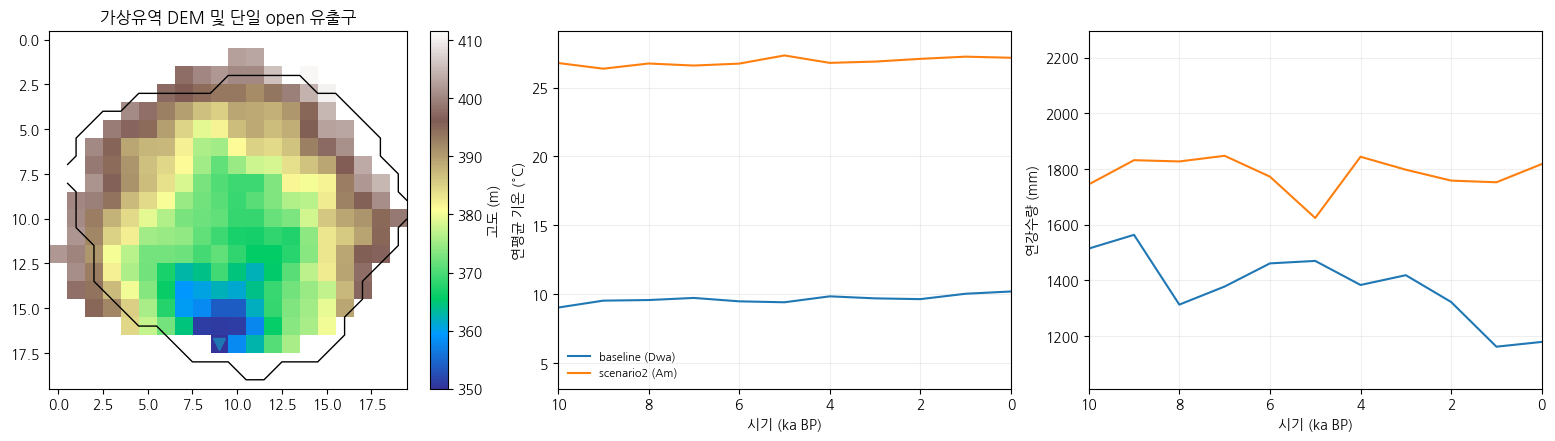

In [65]:
#@title 5. 시나리오 입력자료 생성
import re, shutil, json, numpy as np, pandas as pd, rasterio
from rasterio.transform import from_origin
from pyproj import Transformer
from pathlib import Path

scenario_count=int(scenario_count_widget.value)
start_ka=int(start_ka_widget.value)
end_ka=int(end_ka_widget.value)
if not (0<=end_ka<start_ka<=120):
    raise ValueError("시작시점과 종료시점을 120–0 ka BP 범위에서 지정하십시오.")
period=f"{start_ka}–{end_ka} ka BP"

scenario_configs=[]
for i in range(scenario_count):
    w=scenario_controls[i]
    name=w["name"].value.strip()
    if not re.fullmatch(r"[A-Za-z0-9_-]{1,40}",name):
        raise ValueError(f"시나리오 {i+1} 이름에는 영문·숫자·_·-만 사용할 수 있습니다.")
    scenario_configs.append({
        "name":name,"model":w["model"].value,
        "koppen":w["koppen"].value,
        "representative_id":w["representative"].value,
        "soil_depth_multiplier":float(w["initial_soil_depth_multiplier"].value),
        "uplift_m_per_kyr":float(w["uplift_m_per_kyr"].value),
        "soil_production_a":float(w["soil_production_a"].value),
        "hillslope_c":float(w["hillslope_eemt_c"].value),
        "hillslope_d":float(w["hillslope_biomass_d"].value),
        "fluvial_K0":float(w["fluvial_erodibility_k0"].value)
    })
if len(set(x["name"] for x in scenario_configs))!=len(scenario_configs):
    raise ValueError("시나리오 이름은 중복될 수 없습니다.")

exp_root=ROOT/"teaching_experiments_global120"
exp_root.mkdir(parents=True,exist_ok=True)

# 공통 가상유역
cell_size_m=float(basin_cellsize_widget.value)
target_basin_area_km2=float(basin_area_widget.value)
base_elevation_m=float(basin_base_elev_widget.value)
longitudinal_relief_m=float(basin_long_relief_widget.value)
base_soil_depth_m=float(basin_soil_depth_widget.value)
basin_seed=int(basin_seed_widget.value)
basin_elongation=float(basin_elongation_widget.value)
basin_irregularity=float(basin_irregularity_widget.value)
basin_noise_m=float(basin_noise_widget.value)

dem_common,basin_mask,(outlet_row,outlet_col)=_build_virtual_basin()
grid_size=int(dem_common.shape[0])
actual_basin_area_m2=float(basin_mask.sum()*cell_size_m*cell_size_m)
actual_basin_area_km2=actual_basin_area_m2/1_000_000.0

soil_common=np.where(
    basin_mask,base_soil_depth_m,np.nan
).astype("float32")
texture_common=np.where(
    basin_mask,2.0,np.nan
).astype("float32")

virtual_basin_config={
    "target_basin_area_km2":target_basin_area_km2,
    "actual_basin_area_km2":actual_basin_area_km2,
    "grid_size":grid_size,
    "cell_size_m":cell_size_m,
    "bounding_box_width_m":grid_size*cell_size_m,
    "valid_cell_count":int(basin_mask.sum()),
    "basin_area_m2":actual_basin_area_m2,
    "outlet_row":int(outlet_row),
    "outlet_col":int(outlet_col),
    "base_elevation_m":base_elevation_m,
    "relief_control_m":longitudinal_relief_m,
    "base_soil_depth_m":base_soil_depth_m,
    "shape_seed":basin_seed,
    "elongation":basin_elongation,
    "boundary_irregularity":basin_irregularity,
    "elevation_noise_m":basin_noise_m,
    "boundary_condition":"single open outlet; all remaining basin boundary closed",
}
virtual_basin_table=pd.DataFrame([virtual_basin_config])
print("가상유역 설정")
display(virtual_basin_table)

def make_climate_csv(representative,output_path):
    raw=CLIMATE_MASTER[CLIMATE_MASTER.representative_id==representative].copy()
    if raw.empty: raise ValueError(f"대표 지점이 없습니다: {representative}")
    newages=np.arange(0,121,dtype=int)
    data=[]
    for month in range(1,13):
        source=raw.loc[raw.month==month].sort_values("ka_bp")
        age=source["ka_bp"].to_numpy(float)
        if len(age)<2 or age[0]!=0 or age[-1]!=120:
            raise ValueError(f"{representative} {month}월: 기후 시점 범위 오류")
        for k in newages:
            rec={"ka_bp":int(k),"month":month}
            for key in ("temp_C","precip_mm","cloud_pct","relative_humidity","wind_speed"):
                if key in source:
                    rec[key]=float(np.interp(k,age,source[key].to_numpy(float)))
            data.append(rec)
    df=pd.DataFrame(data)
    df["tmin_C"]=df.groupby("ka_bp")["temp_C"].transform("min")
    df["precip_mm"]=df["precip_mm"].clip(lower=0)
    df["cloud_pct"]=df["cloud_pct"].clip(lower=0,upper=100)
    assert len(df)==121*12 and not df[["temp_C","precip_mm","cloud_pct","tmin_C"]].isna().any().any()
    df.sort_values(["ka_bp","month"],ascending=[False,True]).to_csv(
        output_path,index=False,float_format="%.6f")
    return df

def generate_virtual_basin(folder,lon,lat,soil_factor):
    from rasterio.features import shapes
    folder.mkdir(parents=True,exist_ok=True)

    # 가상유역의 지리좌표는 선택한 기후 대표지점에 두되,
    # 지형·유역형상은 모든 시나리오에서 동일하게 사용
    if lat>=84: epsg=3413
    elif lat<=-80: epsg=3031
    else:
        zone=max(1,min(60,int((lon+180)//6+1)))
        epsg=(32600 if lat>=0 else 32700)+zone

    xx,yy=Transformer.from_crs(4326,epsg,always_xy=True).transform(lon,lat)
    width=grid_size*cell_size_m
    left=xx-width/2
    top=yy+width/2
    transform=from_origin(left,top,cell_size_m,cell_size_m)

    dem_write=np.where(basin_mask,dem_common,-9999.0).astype("float32")
    soil_write=np.where(
        basin_mask,base_soil_depth_m*soil_factor,-9999.0
    ).astype("float32")
    texture_write=np.where(basin_mask,2.0,-9999.0).astype("float32")

    for filename,data in (
        ("dem_virtual.tif",dem_write),
        ("soil_depth_virtual_m.tif",soil_write),
        ("soil_texture_virtual.tif",texture_write)
    ):
        with rasterio.open(
            folder/filename,"w",driver="GTiff",
            width=grid_size,height=grid_size,count=1,
            dtype="float32",crs=f"EPSG:{epsg}",
            transform=transform,nodata=-9999.0
        ) as dst:
            dst.write(data,1)

    # 마스크의 실제 불규칙 경계를 basin polygon으로 저장
    mask_u8=basin_mask.astype("uint8")
    geoms=[
        geom for geom,val in shapes(mask_u8,mask=basin_mask,transform=transform)
        if int(val)==1
    ]
    if len(geoms)!=1:
        raise RuntimeError(f"가상유역 마스크가 단일 연결 유역이 아닙니다: {len(geoms)}개")
    basin_geometry=geoms[0]

    # 경계조건: 이 점 하나만 open, 나머지 유역 경계는 closed
    outlet_x=left+(outlet_col+0.5)*cell_size_m
    outlet_y=top-(outlet_row+0.5)*cell_size_m
    outlet_geometry={"type":"Point","coordinates":[outlet_x,outlet_y]}

    for fname,geometry in (
        ("basin_virtual.geojson",basin_geometry),
        ("outlet_open_free_virtual.geojson",outlet_geometry)
    ):
        feature={
            "type":"FeatureCollection",
            "crs":{"type":"name","properties":{"name":f"EPSG:{epsg}"}},
            "features":[{"type":"Feature","properties":{}, "geometry":geometry}]
        }
        (folder/fname).write_text(
            json.dumps(feature,ensure_ascii=False),encoding="utf-8"
        )

scenario_paths={}
for sc in scenario_configs:
    name=sc["name"]
    row=climate_places.loc[climate_places.representative_id==sc["representative_id"]].iloc[0]
    work=exp_root/name
    inputs=work/"inputs"
    if inputs.exists():shutil.rmtree(inputs)
    inputs.mkdir(parents=True)
    generate_virtual_basin(
        inputs,float(row.source_grid_lon),float(row.source_grid_lat),
        sc["soil_depth_multiplier"]
    )
    clim_path=inputs/"beyer_global_120ka_monthly.csv"
    make_climate_csv(sc["representative_id"],clim_path)
    scenario_paths[name]={"work":work,"inputs":inputs,"rawcsv":clim_path,
                          "soil_path":inputs/"soil_depth_virtual_m.tif"}

scenario_table=pd.DataFrame(scenario_configs)
scenario_table["대표 지역"]=scenario_table["representative_id"].map(
    climate_places.set_index("representative_id")["region_name"]
)
scenario_table["대표지점 표시"]=scenario_table["representative_id"].map(
    climate_places.set_index("representative_id")["place_label"]
)
display(scenario_table)
print(
    f"기간 {period} | 시간간격 1 kyr | "
    f"가상유역 {actual_basin_area_km2:.3f} km² | "
    f"{grid_size}×{grid_size} 격자 | "
    f"해상도 {cell_size_m:g} m | "
    f"경계상자 {grid_size*cell_size_m/1000:.2f} km"
)

import matplotlib.pyplot as plt
from IPython.display import display

annual_rows=[]
for sc in scenario_configs:
    cp=scenario_paths[sc["name"]]["rawcsv"]
    forcing=pd.read_csv(cp)
    yearly=forcing.groupby("ka_bp",as_index=False).agg(
        mean_temp_C=("temp_C","mean"),
        annual_precip_mm=("precip_mm","sum"),
        mean_cloud_pct=("cloud_pct","mean")
    )
    yearly.insert(0,"scenario",sc["name"])
    yearly.insert(1,"model",sc["model"])
    yearly.insert(2,"koppen",sc["koppen"])
    yearly.insert(3,"representative_id",sc["representative_id"])
    annual_rows.append(yearly)
scenario_climate_annual=pd.concat(annual_rows,ignore_index=True)
scenario_climate_annual.to_csv(
    exp_root/"climate_forcing_annual.csv",index=False,encoding="utf-8-sig"
)

fig,axes=plt.subplots(1,3,figsize=(16,4.3),constrained_layout=True)
_x=np.arange(grid_size,dtype=float)*cell_size_m
_y=np.arange(grid_size,dtype=float)*cell_size_m
_extent=[
    -0.5*cell_size_m,(grid_size-0.5)*cell_size_m,
    (grid_size-0.5)*cell_size_m,-0.5*cell_size_m
]
im=axes[0].imshow(
    np.ma.masked_invalid(dem_common),
    cmap="terrain",origin="upper",extent=_extent
)
axes[0].contour(
    _x,_y,basin_mask.astype(float),
    levels=[0.5],colors="black",linewidths=1.0
)
axes[0].plot(
    outlet_col*cell_size_m,outlet_row*cell_size_m,
    marker="v",markersize=9
)
axes[0].set_aspect("equal")
axes[0].set_xlabel("거리 (m)")
axes[0].set_ylabel("거리 (m)")
axes[0].set_title(
    f"가상유역 DEM 및 단일 open 유출구\n"
    f"{actual_basin_area_km2:.3f} km²"
)
fig.colorbar(im,ax=axes[0],fraction=.05,label="고도 (m)")
for sc in scenario_configs:
    data=scenario_climate_annual[scenario_climate_annual.scenario==sc["name"]]
    axes[1].plot(data.ka_bp,data.mean_temp_C,label=f'{sc["name"]} ({sc["koppen"]})')
    axes[2].plot(data.ka_bp,data.annual_precip_mm,label=f'{sc["name"]} ({sc["koppen"]})')
axes[1].set_ylabel("연평균 기온 (°C)")
axes[2].set_ylabel("연강수량 (mm)")
for ax in axes[1:]:
    ax.set_xlabel("시기 (ka BP)")
    ax.set_xlim(start_ka,end_ka)
    ax.grid(alpha=.2)
axes[1].legend(frameon=False,fontsize=8)
plt.show()



## 6. 시나리오 일괄 실행


In [66]:
#@title 6. 시나리오 실행
import os, time, warnings
import numpy as np
import pandas as pd
from pb4studio.pelletier_geomorph import PelletierStrictConfig
from pb4studio.snapshots import snapshot_dir_name

pb4_threads=int(globals().get("PB4_THREADS",max(1,min(int(os.cpu_count() or 1),2))))
times=np.round(np.arange(start_ka,end_ka-0.01,-1.0),6)
assert len(times)>1 and abs(float(times[-1])-end_ka)<1e-5
# 5 kyr 간격으로 자동 저장. 시작·종료시점은 항상 포함
_snap_list=[float(start_ka)]
_next=float(start_ka)-5.0
while _next>float(end_ka)+1e-9:
    _snap_list.append(float(_next))
    _next-=5.0
if abs(_snap_list[-1]-float(end_ka))>1e-9:
    _snap_list.append(float(end_ka))
snaps=tuple(round(x,6) for x in _snap_list)
print("지도·공간분포 저장시점 (ka BP):",", ".join(f"{x:g}" for x in snaps))

def _fmt_seconds(seconds):
    seconds=max(0,int(round(seconds)))
    h,rem=divmod(seconds,3600)
    m,s=divmod(rem,60)
    return f"{h:d}:{m:02d}:{s:02d}" if h else f"{m:02d}:{s:02d}"

scenario_outputs={}
scenario_runtime=[]
overall_start=time.perf_counter()

for scenario_no,sc in enumerate(scenario_configs,1):
    name=sc["name"]
    paths=scenario_paths[name]
    work=paths["work"]
    inputs=paths["inputs"]
    rawcsv=paths["rawcsv"]
    soil_path=paths["soil_path"]

    out_dir=work/"output"
    if out_dir.exists():
        shutil.rmtree(out_dir)
    out_dir.mkdir(parents=True,exist_ok=True)

    cfg=RunConfig(
        mode=RunMode.STATIC if sc["model"]=="정적" else RunMode.DYNAMIC,
        inputs=InputPaths(
            dem_path=str(inputs/"dem_virtual.tif"),
            climate_nc_path=str(rawcsv),
            soil_depth_path=str(soil_path),
            soil_texture_path=str(inputs/"soil_texture_virtual.tif"),
            basin_polygon_path=str(inputs/"basin_virtual.geojson"),
            open_free_shp=str(inputs/"outlet_open_free_virtual.geojson"),
            open_fixed_slope_shp=None,
            soil_depth_unit="m",
            validation_points_csv="",
        ),
        time=TimeConfig(
            start_ka=float(start_ka),
            end_ka=float(end_ka),
            interval_kyr=1.0,
            snapshot_ka=snaps,
        ),
        resolution_m_override=float(cell_size_m),
        requested_core_count=pb4_threads,
        pelletier=PelletierStrictConfig(
            uplift_m_per_kyr=sc["uplift_m_per_kyr"],
            p0_base_m_per_kyr=sc["soil_production_a"],
            kd_c_eemt_m_per_kyr_per_mj=sc["hillslope_c"],
            kd_d_agb_m_per_kyr_per_kgm2=sc["hillslope_d"],
            k0_regolith=sc["fluvial_K0"],
            hillslope_critical_slope=1.50,
        ),
        science=ScienceConfig(
            biome4_variant="mckenzie2003",
            force_compile_biome4=False,
            validation_accuracy_method="per_output_time",
            basin_presence_min_fraction=0.01,
        ),
        output_dir=str(out_dir),
    )

    cfg.to_json(work/"run_config.json")
    settings={
        "scenario_number":scenario_no,
        "scenario_count":scenario_count,
        "scenario_name":name,
        "model":sc["model"],
        "koppen":sc["koppen"],
        "representative_id":sc["representative_id"],
        "soil_depth_multiplier":sc["soil_depth_multiplier"],
        "start_ka":start_ka,
        "end_ka":end_ka,
        "u_m_per_kyr":sc["uplift_m_per_kyr"],
        "p0_a":sc["soil_production_a"],
        "kd_c":sc["hillslope_c"],
        "kd_d":sc["hillslope_d"],
        "K0":sc["fluvial_K0"],
        "model_sha256":checksum,
        "biome4_openmp_threads":pb4_threads,
    }
    (work/"teaching_settings.json").write_text(
        json.dumps(settings,ensure_ascii=False,indent=2),encoding="utf-8"
    )

    state={"case":None,"case_start":None}
    def progress(case_label,step_index,n_steps,ka,_name=name,_state=state):
        now=time.perf_counter()
        if _state["case"]!=case_label:
            _state["case"]=case_label
            _state["case_start"]=now
            print(f"\n[{_name} / {case_label}] 계산 시작 | {n_steps}시점",flush=True)
        elapsed=now-_state["case_start"]
        completed=max(int(step_index),0)
        if step_index==0 or step_index==n_steps-1 or step_index<10 or step_index%10==0:
            if completed>0:
                sec_per_step=elapsed/completed
                eta=sec_per_step*max(n_steps-completed,0)
                print(
                    f"[{_name} / {case_label}] {step_index+1}/{n_steps}, {ka:.1f} ka BP"
                    f" | 경과 {_fmt_seconds(elapsed)} | 남은 시간 약 {_fmt_seconds(eta)}",
                    flush=True
                )
            else:
                print(f"[{_name} / {case_label}] 1/{n_steps}, {ka:.1f} ka BP",flush=True)

    _place_name=climate_places.loc[
        climate_places.representative_id==sc["representative_id"],"landmark_name_ko"
    ].iloc[0]
    print(
        f"\n===== 시나리오 {scenario_no}/{scenario_count}: {name} ====="
        f"\n쾨펜 기후형 {sc['koppen']} | 도시·지역 {_place_name} ({sc['representative_id']}) | 모델 {sc['model']}",
        flush=True
    )
    start=time.perf_counter()
    try:
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",message="Mean of empty slice",
                category=RuntimeWarning,module=r"pb4studio\.runner"
            )
            runner.run(cfg,progress_callback=progress)
    except KeyboardInterrupt:
        print(f"\n{name} 실행이 중단되었습니다. 계산 예외가 아니라 Jupyter 중단 신호입니다.",flush=True)
        raise

    elapsed=time.perf_counter()-start

    for label,subdir in [(sc["model"],"model_static" if sc["model"]=="정적" else "model_dynamic")]:
        summary_file=out_dir/subdir/"summary_timeseries.csv"
        assert summary_file.is_file(),f"{name}/{label}: summary_timeseries.csv 없음"
        summary=pd.read_csv(summary_file)
        assert len(summary)==len(times),f"{name}/{label}: 시점 수 불일치"
        assert summary["ka_bp"].is_unique,f"{name}/{label}: 중복 시점"
        assert np.allclose(summary["ka_bp"].to_numpy(float),times,atol=1e-6,rtol=0)
        for col in ("mean_elevation_m","mean_soil_depth_m","mean_npp"):
            assert np.isfinite(summary[col].to_numpy(float)).all(),f"{name}/{label}: {col} 비정상 값"

    # BIOME4 native biome 출력 누락은 지도 단계 전에 확인
    for age in snaps:
        biome_file=out_dir/("model_static" if sc["model"]=="정적" else "model_dynamic")/snapshot_dir_name(float(age))/"biome4_full_id.tif"
        if not biome_file.is_file():
            raise FileNotFoundError(f"BIOME4 생물군계 GeoTIFF 저장 실패: {biome_file}")
    if "biome4_full_id_counts" not in summary.columns:
        raise RuntimeError(f"{name}: BIOME4 생물군계 시계열 집계 누락")

    scenario_outputs[name]=out_dir
    scenario_runtime.append({"scenario":name,"model":sc["model"],"koppen":sc["koppen"],"representative_id":sc["representative_id"],"elapsed_s":elapsed})
    print(f"{name} 완료 | {_fmt_seconds(elapsed)}",flush=True)

reference_scenario=scenario_configs[0]["name"]
work=scenario_paths[reference_scenario]["work"]
inputs=scenario_paths[reference_scenario]["inputs"]
rawcsv=scenario_paths[reference_scenario]["rawcsv"]
soil_path=scenario_paths[reference_scenario]["soil_path"]
out_dir=scenario_outputs[reference_scenario]
experiment_name=reference_scenario
CASE_DIRS={"정적":"model_static","동적":"model_dynamic"}
SCENARIO_MODELS={sc["name"]:sc["model"] for sc in scenario_configs}
selected_ages=tuple(float(x) for x in snaps)

registry={
    "period":period,
    "start_ka":start_ka,
    "end_ka":end_ka,
    "reference_scenario":reference_scenario,
    "virtual_basin":virtual_basin_config,
    "scenarios":scenario_configs,
    "interval_kyr":1.0,
}
registry_path=exp_root/"scenario_registry.json"
registry_path.write_text(json.dumps(registry,ensure_ascii=False,indent=2),encoding="utf-8")

print("\n전체 시나리오 실행 완료")
display(pd.DataFrame(scenario_runtime).assign(elapsed_min=lambda x:x.elapsed_s/60).round(2))
print("기준 시나리오:",reference_scenario)


지도·공간분포 저장시점 (ka BP): 10, 5, 0

===== 시나리오 1/2: baseline =====
쾨펜 기후형 Dwa | 도시·지역 대한민국 서울 (KR_SEOUL) | 모델 동적

[baseline / 동적모델] 계산 시작 | 11시점
[baseline / 동적모델] 1/11, 10.0 ka BP
[baseline / 동적모델] 2/11, 9.0 ka BP | 경과 00:10 | 남은 시간 약 01:36
[baseline / 동적모델] 3/11, 8.0 ka BP | 경과 00:25 | 남은 시간 약 01:51
[baseline / 동적모델] 4/11, 7.0 ka BP | 경과 00:34 | 남은 시간 약 01:31
[baseline / 동적모델] 5/11, 6.0 ka BP | 경과 00:46 | 남은 시간 약 01:20
[baseline / 동적모델] 6/11, 5.0 ka BP | 경과 00:53 | 남은 시간 약 01:03
[baseline / 동적모델] 7/11, 4.0 ka BP | 경과 01:01 | 남은 시간 약 00:51
[baseline / 동적모델] 8/11, 3.0 ka BP | 경과 01:12 | 남은 시간 약 00:41
[baseline / 동적모델] 9/11, 2.0 ka BP | 경과 01:20 | 남은 시간 약 00:30
[baseline / 동적모델] 10/11, 1.0 ka BP | 경과 01:31 | 남은 시간 약 00:20
[baseline / 동적모델] 11/11, 0.0 ka BP | 경과 01:39 | 남은 시간 약 00:10
baseline 완료 | 01:40

===== 시나리오 2/2: scenario2 =====
쾨펜 기후형 Am | 도시·지역 아마존 분지 (AMAZON_BASIN) | 모델 동적

[scenario2 / 동적모델] 계산 시작 | 11시점
[scenario2 / 동적모델] 1/11, 10.0 ka BP
[scenario2 / 동적모델] 2/11, 9.0 ka BP | 경과 00

,scenario,model,koppen,representative_id,elapsed_s,elapsed_min
0,baseline,동적,Dwa,KR_SEOUL,99.99,1.67
1,scenario2,동적,Am,AMAZON_BASIN,82.93,1.38


기준 시나리오: baseline


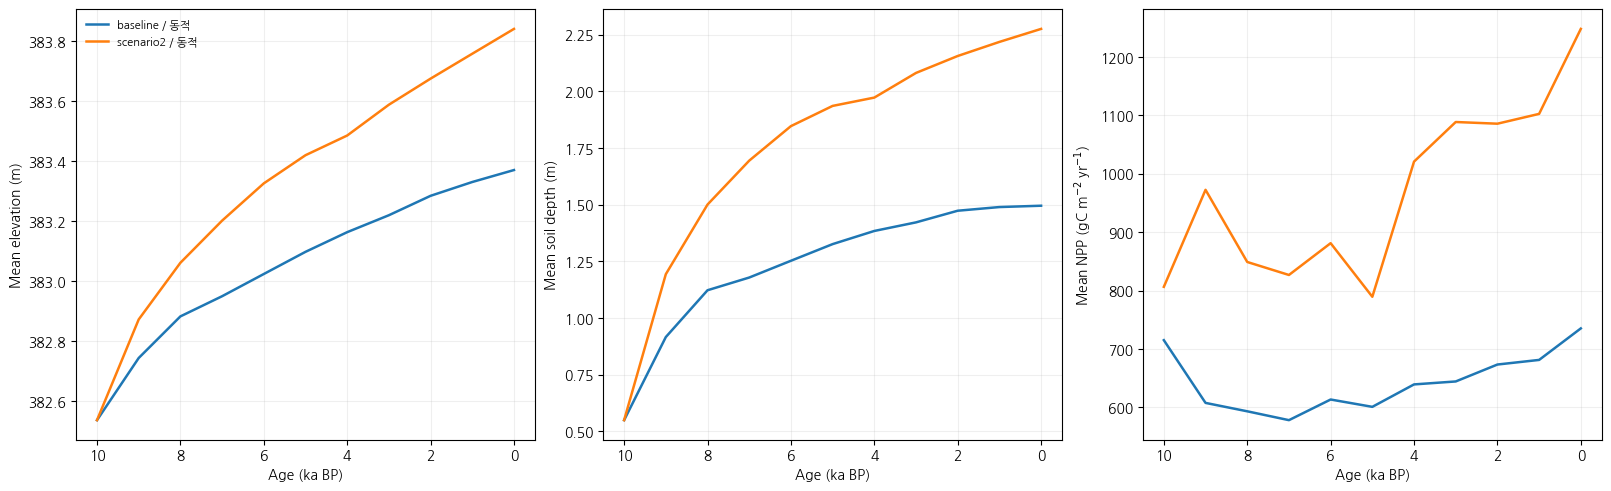

종료시점


,scenario,model,mean_elevation_m,mean_soil_depth_m,mean_npp
10,baseline,동적,383.371,1.496,735.171
21,scenario2,동적,383.842,2.275,1248.333


In [67]:
#@title 7. 시계열 비교
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

timeseries_rows=[]

for sc in scenario_configs:
    name=sc["name"]

    for model,subdir in [(sc["model"],CASE_DIRS[sc["model"]])]:
        df=pd.read_csv(scenario_outputs[name]/subdir/"summary_timeseries.csv")
        tmp=df.copy()
        tmp["scenario"]=name
        tmp["model"]=model
        timeseries_rows.append(tmp)

scenario_timeseries=pd.concat(timeseries_rows,ignore_index=True)

comparison_report=exp_root/"comparison_report"
comparison_report.mkdir(parents=True,exist_ok=True)
for old_name in (
    "within_scenario_dynamic_minus_static.csv",
    "between_scenario_minus_reference.csv",
    "grid_biome4_agreement.csv",
    "grid_difference_statistics.csv",
    "scenario_end_comparison.csv",
):
    old_file=comparison_report/old_name
    if old_file.exists():
        old_file.unlink()

scenario_timeseries.to_csv(
    comparison_report/"all_scenarios_timeseries.csv",
    index=False,
    encoding="utf-8-sig"
)

fig,axes=plt.subplots(1,3,figsize=(16,4.8),constrained_layout=True)

metrics=[
    ("mean_elevation_m","Mean elevation (m)"),
    ("mean_soil_depth_m","Mean soil depth (m)"),
    ("mean_npp","Mean NPP (gC m$^{-2}$ yr$^{-1}$)")
]

for ax,(col,ylabel) in zip(axes,metrics):

    for (scenario,model),g in scenario_timeseries.groupby(["scenario","model"]):
        g=g.sort_values("ka_bp",ascending=False)
        ls="-" if model=="동적" else "--"
        ax.plot(
            g["ka_bp"],
            g[col],
            linestyle=ls,
            lw=1.8,
            label=f"{scenario} / {model}"
        )

    ax.invert_xaxis()
    ax.set_xlabel("Age (ka BP)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.2)

axes[0].legend(frameon=False,fontsize=8)
plt.show()

end_summary=scenario_timeseries[
    np.isclose(
        scenario_timeseries["ka_bp"].to_numpy(float),
        float(end_ka),
        atol=1e-6
    )
][[
    "scenario","model",
    "mean_elevation_m","mean_soil_depth_m","mean_npp"
]]

print("종료시점")
display(end_summary.round(3))


## 8. 5 kyr 간격 시나리오별 공간분포와 BIOME4 생물군계

### BIOME4 생물군계 분류

| ID | BIOME4 원본 명칭 | 국문 명칭 | 생태적 특성 |
|---:|---|---|---|
| 1 | Tropical evergreen forest | 열대 상록수림 | 연중 고온다습하여 상록활엽수가 밀집한 숲. |
| 2 | Tropical semi-deciduous forest | 열대 반낙엽수림 | 열대의 계절적 건기에 일부 교목이 잎을 떨어뜨리는 숲. |
| 3 | Tropical deciduous forest/woodland | 열대 낙엽수림 및 소림 | 건기가 뚜렷하여 낙엽교목이 우세하고 수관이 비교적 개방된 숲. |
| 4 | Temperate deciduous forest | 온대 낙엽활엽수림 | 계절별 기온 변화에 따라 활엽교목이 겨울철에 낙엽하는 숲. |
| 5 | Temperate conifer forest | 온대 침엽수림 | 온대 기후에서 침엽교목이 우세한 숲. |
| 6 | Warm mixed forest | 난온대 혼효림 | 비교적 온난한 온대에서 상록성·낙엽성 교목 등이 함께 나타나는 숲. |
| 7 | Cool mixed forest | 냉온대 혼효림 | 냉량한 온대에서 낙엽활엽수와 침엽수가 함께 우세한 숲. |
| 8 | Cool conifer forest | 냉온대 침엽수림 | 냉량한 기후에서 침엽교목이 우세한 숲. |
| 9 | Cold mixed forest | 한랭 혼효림 | 한랭한 지역에서 침엽교목과 낙엽교목이 혼재하는 숲. |
| 10 | Evegreen taiga/montane forest | 상록 타이가 및 산지림 | 아한대 또는 고산의 긴 추위에 적응한 상록침엽수림. |
| 11 | Deciduous taiga/montane forest | 낙엽 타이가 및 산지림 | 아한대 또는 고산에서 낙엽성 교목이 우세한 숲. |
| 12 | Tropical savanna | 열대 사바나 | 열대의 계절적 건조 환경에서 초본층과 드문드문 선 교목이 공존하는 식생. |
| 13 | Tropical xerophytic shrubland | 열대 건생관목림 | 강수량이 적은 열대에서 건조에 적응한 관목이 우세한 식생. |
| 14 | Temperate xerophytic shrubland | 온대 건생관목림 | 건조한 온대에서 내건성 관목이 우세한 식생. |
| 15 | Temperate sclerophyll woodland | 온대 경엽수 소림 | 여름철 건조 등에 적응한 단단한 잎의 목본이 형성한 개방된 숲. |
| 16 | Temperate broadleaved savanna | 온대 활엽수 사바나 | 온대에서 초본층과 개방된 활엽교목층이 함께 나타나는 식생. |
| 17 | Open conifer woodland | 개방 침엽수림 | 침엽교목이 낮은 밀도로 분포하여 수관 사이가 개방된 숲. |
| 18 | Boreal parkland | 아한대 소림 및 개방식생 | 아한대 수목한계 부근에서 드문드문 선 교목과 저목·초본이 공존하는 식생. |
| 19 | Tropical grassland | 열대 초원 | 열대에서 화본과 초본이 주로 우세하고 교목 피복이 낮은 초원. |
| 20 | Temperate grassland | 온대 초원 | 온대에서 초본류가 우세하며 교목층이 거의 발달하지 않은 초원. |
| 21 | Desert | 사막 | 수분 부족으로 식생 피복과 생산성이 매우 낮은 지역. |
| 22 | Steppe tundra | 스텝 툰드라 | 한랭하고 비교적 건조한 조건에서 초본과 낮은 툰드라 식생이 혼재하는 지역. |
| 23 | Shrub tundra | 관목 툰드라 | 수목한계 너머의 한랭 지역에서 관목이 우세한 툰드라. |
| 24 | Dwarf shrub tundra | 왜성관목 툰드라 | 낮은 온도와 짧은 생육기에 적응한 왜성관목이 우세한 툰드라. |
| 25 | Prostrate shrub tundra | 포복관목 툰드라 | 지표 가까이 기는 관목이 우세한 한랭지 툰드라. |
| 26 | Cushion-forbs, lichen and moss | 방석형 초본·지의류·선태류 식생 | 매우 한랭한 환경에서 방석형 초본, 지의류 및 선태류가 드물게 분포하는 식생. |
| 27 | Barren | 무식생지 | 토양·기후 조건 등으로 식물이 거의 존재하지 않는 지표. |
| 28 | Land ice | 빙설 피복지 | 지표가 지속적인 얼음으로 덮여 육상식생이 형성되지 않는 지역. |

참고: [Kaplan et al. (2003), BIOME4 모형](https://pmip2.lsce.ipsl.fr/synth/biome4.shtml), [Kaplan et al. (2002), BIOME4 생물군계 표](https://doi.org/10.1029/2001GB001403).



### BIOME4 생물군계·PFT 대표 식생 예시의 근거

BIOME4는 개별 종을 직접 모의하는 종분포모형이 아니라, 생리·형태·생활사가 비슷한 식물기능유형(PFT)의 생산성과 생물기후 제약을 계산하고 그 조합으로 생물군계를 판정합니다. 아래의 종·식생 예시는 **모델에 종 목록이 들어 있다는 뜻이 아니라**, 각 PFT·생물군계와 현실 식생을 연결하기 위한 대응 예시입니다.

- Kaplan, J. O., Prentice, I. C., & Buchmann, N. (2002). *The stable carbon isotope composition of the terrestrial biosphere: Modeling at scales from the leaf to the globe*. Global Biogeochemical Cycles, 16(4). DOI 10.1029/2001GB001403. BIOME4 PFT·biome, cold-deciduous tree 예시(*Larix, Betula, Sorbus*), C4 사막관목 예시(*Atriplex, Euphorbia*)를 확인함.
- Kaplan, J. O., et al. (2003). *Climate change and Arctic ecosystems: 2. Modeling, paleodata-model comparisons, and future projections*. Journal of Geophysical Research, 108(D19), 8171. DOI 10.1029/2002JD002559. 저·고관목, 직립 왜성관목, 포복 왜성관목, 방석형 초본, graminoid–forb tundra의 Typical Taxa를 Table 1에서 확인함.
- Ni, J. (2000). *Modelling the vegetation of China using the process-based equilibrium terrestrial biosphere model BIOME3*. Global Ecology and Biogeography, 9, 463–479. 열대우림, 열대 계절림, 온대 상록활엽수림, 온대·아한대 침엽수림, 낙엽수림의 대표 우점속을 확인함.
- Ni, J., & Herzschuh, U. (2011). *Simulating Biome Distribution on the Tibetan Plateau Using a Modified Global Vegetation Model*. Arctic, Antarctic, and Alpine Research, 43(3), 429–441. DOI 10.1657/1938-4246-43.3.429. BIOME4-Tibet의 13개 PFT 명칭과 *Stipa, Festuca, Carex, Kobresia* 등 티베트 steppe·tundra 식생 대응을 확인함.
- Bradshaw, C. D., et al. (2025). *MioVeg1: A Global Middle Miocene Vegetation Reconstruction for Climate Modeling*. Paleoceanography and Paleoclimatology, 40. DOI 10.1029/2025PA005213. 최신 문헌에서 BIOME4의 13개 PFT와 28개 biome 명칭을 재확인함.
- Edwards, E. J., et al. (2010). *Phylogenetic analyses reveal the shady history of C4 grasses*. Proceedings of the National Academy of Sciences, 107, 2532–2537. DOI 10.1073/pnas.0909672107. 열대·아열대 초원과 사바나에서 C4 초본이 우세한다는 기능적 대응을 확인함.


공간분포는 연도별 묶음이 아니라 항목별로 정리합니다. 각 항목에서 5 kyr 간격 시점을 순서대로 비교합니다.

===== 토심 (m) =====


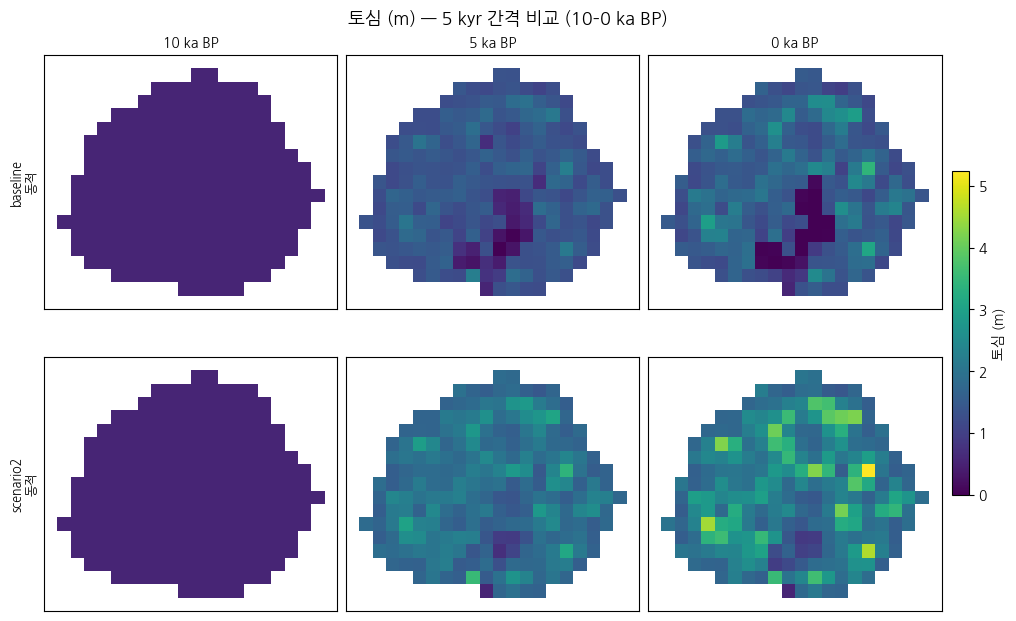


===== BIOME4 생물군계 =====


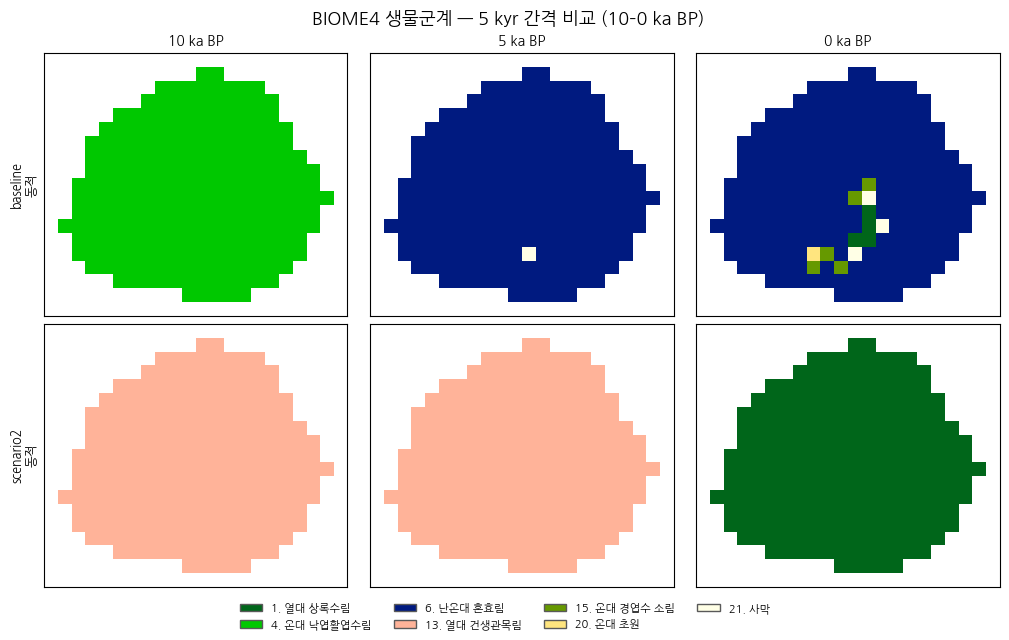


===== 고도 (m) =====


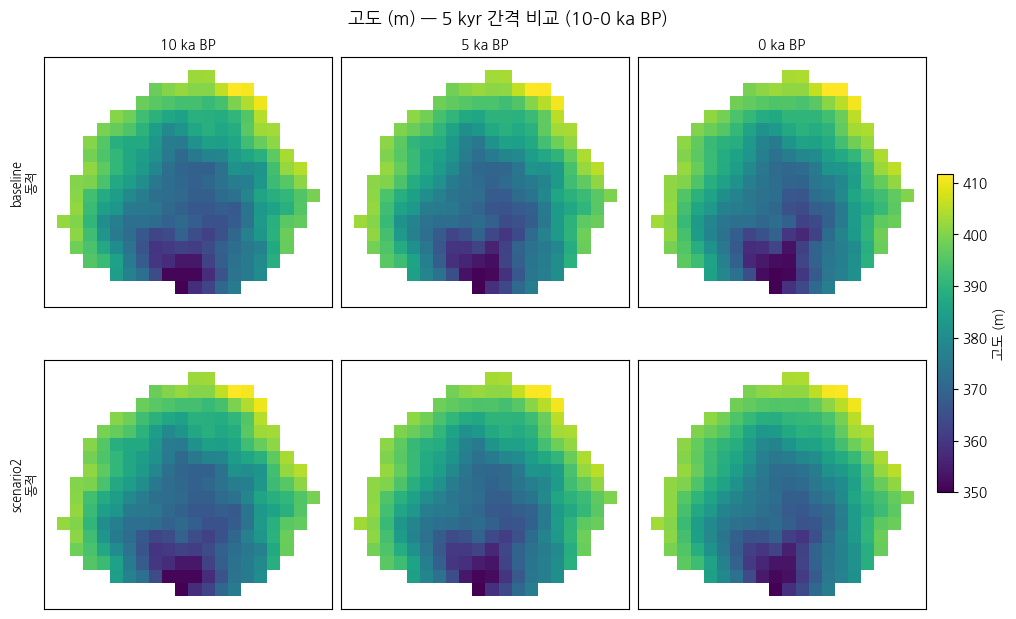


===== NPP =====


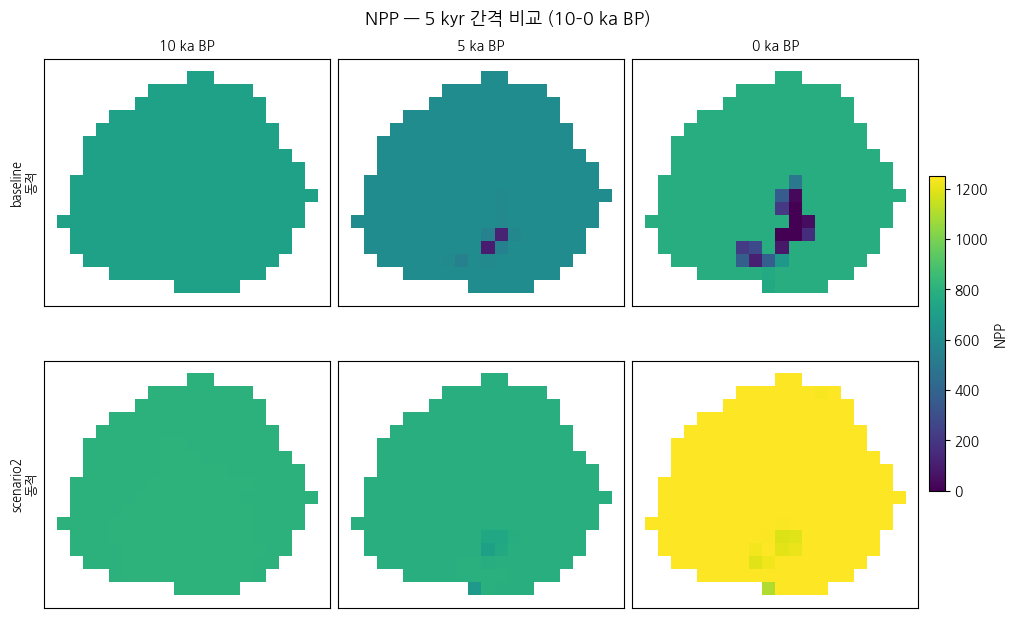

항목별 5 kyr 지도 저장: /content/yongneup_biome4_teaching/teaching_experiments_global120/comparison_report/maps_5k_by_variable


In [68]:
#@title 8. 항목별 5 kyr 간격 공간분포 비교
from pb4studio.snapshots import snapshot_dir_name
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import rasterio, numpy as np, pandas as pd
from pathlib import Path

BIOME4_NAMES={
    1:"Tropical evergreen forest",
    2:"Tropical semi-deciduous forest",
    3:"Tropical deciduous forest/woodland",
    4:"Temperate deciduous forest",
    5:"Temperate conifer forest",
    6:"Warm mixed forest",
    7:"Cool mixed forest",
    8:"Cool conifer forest",
    9:"Cold mixed forest",
    10:"Evegreen taiga/montane forest",
    11:"Deciduous taiga/montane forest",
    12:"Tropical savanna",
    13:"Tropical xerophytic shrubland",
    14:"Temperate xerophytic shrubland",
    15:"Temperate sclerophyll woodland",
    16:"Temperate broadleaved savanna",
    17:"Open conifer woodland",
    18:"Boreal parkland",
    19:"Tropical grassland",
    20:"Temperate grassland",
    21:"Desert",
    22:"Steppe tundra",
    23:"Shrub tundra",
    24:"Dwarf shrub tundra",
    25:"Prostrate shrub tundra",
    26:"Cushion-forbs, lichen and moss",
    27:"Barren",
    28:"Land ice",
}
BIOME4_NAMES_KO={
    1:"열대 상록수림",
    2:"열대 반낙엽수림",
    3:"열대 낙엽수림 및 소림",
    4:"온대 낙엽활엽수림",
    5:"온대 침엽수림",
    6:"난온대 혼효림",
    7:"냉온대 혼효림",
    8:"냉온대 침엽수림",
    9:"한랭 혼효림",
    10:"상록 타이가 및 산지림",
    11:"낙엽 타이가 및 산지림",
    12:"열대 사바나",
    13:"열대 건생관목림",
    14:"온대 건생관목림",
    15:"온대 경엽수 소림",
    16:"온대 활엽수 사바나",
    17:"개방 침엽수림",
    18:"아한대 소림 및 개방식생",
    19:"열대 초원",
    20:"온대 초원",
    21:"사막",
    22:"스텝 툰드라",
    23:"관목 툰드라",
    24:"왜성관목 툰드라",
    25:"포복관목 툰드라",
    26:"방석형 초본·지의류·선태류 식생",
    27:"무식생지",
    28:"빙설 피복지",
}
BIOME4_DESCRIPTIONS_KO={
    1:"연중 고온다습하여 상록활엽수가 밀집한 숲.",
    2:"열대의 계절적 건기에 일부 교목이 잎을 떨어뜨리는 숲.",
    3:"건기가 뚜렷하여 낙엽교목이 우세하고 수관이 비교적 개방된 숲.",
    4:"계절별 기온 변화에 따라 활엽교목이 겨울철에 낙엽하는 숲.",
    5:"온대 기후에서 침엽교목이 우세한 숲.",
    6:"비교적 온난한 온대에서 상록성·낙엽성 교목 등이 함께 나타나는 숲.",
    7:"냉량한 온대에서 낙엽활엽수와 침엽수가 함께 우세한 숲.",
    8:"냉량한 기후에서 침엽교목이 우세한 숲.",
    9:"한랭한 지역에서 침엽교목과 낙엽교목이 혼재하는 숲.",
    10:"아한대 또는 고산의 긴 추위에 적응한 상록침엽수림.",
    11:"아한대 또는 고산에서 낙엽성 교목이 우세한 숲.",
    12:"열대의 계절적 건조 환경에서 초본층과 드문드문 선 교목이 공존하는 식생.",
    13:"강수량이 적은 열대에서 건조에 적응한 관목이 우세한 식생.",
    14:"건조한 온대에서 내건성 관목이 우세한 식생.",
    15:"여름철 건조 등에 적응한 단단한 잎의 목본이 형성한 개방된 숲.",
    16:"온대에서 초본층과 개방된 활엽교목층이 함께 나타나는 식생.",
    17:"침엽교목이 낮은 밀도로 분포하여 수관 사이가 개방된 숲.",
    18:"아한대 수목한계 부근에서 드문드문 선 교목과 저목·초본이 공존하는 식생.",
    19:"열대에서 화본과 초본이 주로 우세하고 교목 피복이 낮은 초원.",
    20:"온대에서 초본류가 우세하며 교목층이 거의 발달하지 않은 초원.",
    21:"수분 부족으로 식생 피복과 생산성이 매우 낮은 지역.",
    22:"한랭하고 비교적 건조한 조건에서 초본과 낮은 툰드라 식생이 혼재하는 지역.",
    23:"수목한계 너머의 한랭 지역에서 관목이 우세한 툰드라.",
    24:"낮은 온도와 짧은 생육기에 적응한 왜성관목이 우세한 툰드라.",
    25:"지표 가까이 기는 관목이 우세한 한랭지 툰드라.",
    26:"매우 한랭한 환경에서 방석형 초본, 지의류 및 선태류가 드물게 분포하는 식생.",
    27:"토양·기후 조건 등으로 식물이 거의 존재하지 않는 지표.",
    28:"지표가 지속적인 얼음으로 덮여 육상식생이 형성되지 않는 지역.",
}
BIOME4_EXAMPLES_KO={
    1:"아마존·콩고 분지의 저지대 상록활엽 열대우림",
    2:"열대 계절림의 반상록·반낙엽 수림",
    3:"몬순성 열대 건조낙엽수림·소림",
    4:"유럽·동아시아·북미의 온대 낙엽활엽수림",
    5:"소나무·전나무류가 우세한 온대 상록침엽수림",
    6:"동아시아형 난온대 상록활엽수–낙엽수–침엽수 혼효림",
    7:"냉온대 낙엽활엽수–침엽수 혼효림",
    8:"냉량 산지의 가문비나무·전나무형 침엽수림",
    9:"침엽수와 자작나무·낙엽성 목본이 섞인 한랭 혼효림",
    10:"가문비나무·소나무형 상록 타이가 및 고산 침엽수림",
    11:"낙엽송(Larix)형 낙엽 타이가 및 한랭 산지 낙엽림",
    12:"C4 초본층과 산재한 교목이 공존하는 열대 사바나",
    13:"열대 반건조 지역의 가시관목·건생관목림",
    14:"Artemisia 등 내건성 관목이 우세한 온대 건조 관목·스텝",
    15:"지중해성 상록 경엽 관목림·소림(마키·상록참나무형)",
    16:"초본층과 개방형 낙엽활엽 교목이 공존하는 온대 소림",
    17:"건조·한랭지의 개방형 소나무·향나무류 침엽수림",
    18:"수목한계 부근의 forest–tundra·boreal parkland",
    19:"C4 초본이 우세한 열대 초원",
    20:"프레리·스텝 등 온대 초원(C3 중심, 지역에 따라 C4 혼재)",
    21:"건생관목·초본이 드물게 산재하는 사막 식생",
    22:"Stipa·Festuca·Carex·Kobresia 등 초본·사초류가 나타나는 graminoid–forb/steppe tundra",
    23:"Alnus·Betula·Salix·Pinus pumila 등이 나타나는 저·고관목 툰드라",
    24:"Betula·Cassiope·Empetrum·Salix·Vaccinium 등이 나타나는 직립 왜성관목 툰드라",
    25:"Salix·Dryas·Pedicularis 등이 나타나는 포복 왜성관목 툰드라",
    26:"Papaver·Draba·Saxifragaceae·Caryophyllaceae와 지의류·선태류가 나타나는 방석형 초본 툰드라",
    27:"노출 암설·극건조/극한 지역의 거의 무식생 지표",
    28:"빙상·빙하"
}

BIOME4_EXAMPLE_SOURCE={
    **{i:"Kaplan et al. (2002) biome; Ni (2000) representative dominants" for i in range(1,12)},
    12:"Kaplan et al. (2002); Edwards et al. (2010)",
    13:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
    14:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
    15:"Kaplan et al. (2002); Ni (2000)",
    16:"Kaplan et al. (2002); Ni (2000)",
    17:"Kaplan et al. (2002); Ni (2000)",
    18:"Kaplan et al. (2002); Kaplan et al. (2003)",
    19:"Kaplan et al. (2002); Edwards et al. (2010)",
    20:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
    21:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
    22:"Kaplan et al. (2003) Table 1; Ni & Herzschuh (2011) Table 2",
    23:"Kaplan et al. (2003) Table 1",
    24:"Kaplan et al. (2003) Table 1",
    25:"Kaplan et al. (2003) Table 1",
    26:"Kaplan et al. (2003) Table 1; Ni & Herzschuh (2011) Table 2",
    27:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
    28:"Kaplan et al. (2002); Ni & Herzschuh (2011)",
}

print("BIOME4 생물군계와 대표 식생 예시")
print(
    "※ BIOME4는 종을 직접 모의하지 않습니다. 아래 예시는 각 생물군계를 "
    "현실 식생과 연결하기 위한 교육용 대응 예시이며, 모델의 고정 종 조성을 뜻하지 않습니다."
)
biome_reference_table=pd.DataFrame([
    {
        "ID":i,
        "BIOME4 원명":BIOME4_NAMES[i],
        "국문명":BIOME4_NAMES_KO[i],
        "대표 식생 예시":BIOME4_EXAMPLES_KO[i],
        "설명":BIOME4_DESCRIPTIONS_KO[i],
        "근거":BIOME4_EXAMPLE_SOURCE[i],
    }
    for i in range(1,29)
])
display(biome_reference_table)
biome_reference_table.to_csv(
    comparison_report/"biome4_reference_examples.csv",
    index=False,encoding="utf-8-sig"
)

VEGETATION_SOURCE_NOTES={
    "Bradshaw et al. (2025)":"BIOME4의 13개 PFT와 28개 biome 명칭 재확인",
    "Kaplan et al. (2002)":"BIOME4 PFT·biome; Larix/Betula/Sorbus 및 Atriplex/Euphorbia 예시",
    "Kaplan et al. (2003)":"고위도 PFT와 tundra biome Typical Taxa (Table 1)",
    "Ni (2000)":"BIOME 계열 biome에 대응하는 중국 식생형과 대표 우점속",
    "Ni & Herzschuh (2011)":"BIOME4-Tibet PFT와 Tibetan steppe/tundra 식생 대응 (Table 1–2)",
    "Edwards et al. (2010)":"열대·아열대 초원·사바나의 C4 grass 우세",
}
vegetation_source_table=pd.DataFrame([
    {"인용":k,"확인 내용":v} for k,v in VEGETATION_SOURCE_NOTES.items()
])
print("대표 식생 예시는 모델 입력 종 목록이 아니라 현실 식생의 대응 예시입니다.")
display(vegetation_source_table)
vegetation_source_table.to_csv(
    comparison_report/"vegetation_example_sources.csv",
    index=False,encoding="utf-8-sig"
)

BIOME4_COLORS={
    1:"#00661a",2:"#4d801a",3:"#99661a",4:"#00c800",
    5:"#006666",6:"#001a80",7:"#ccffcc",8:"#009933",
    9:"#80334d",10:"#1a1ae6",11:"#33ccff",12:"#b3e61a",
    13:"#ffb399",14:"#ffd9b3",15:"#669900",16:"#cccc00",
    17:"#ff99e6",18:"#9b7fff",19:"#e6b34d",20:"#ffe57f",
    21:"#ffffe6",22:"#e6e600",23:"#66e680",24:"#808033",
    25:"#cc9999",26:"#b399ff",27:"#ccccb3",28:"#ccffff",
}
biome4_cmap=ListedColormap([BIOME4_COLORS[i] for i in range(1,29)])
biome4_norm=BoundaryNorm(np.arange(0.5,29.5,1),biome4_cmap.N)

biome4_cmap=ListedColormap([BIOME4_COLORS[i] for i in range(1,29)])
biome4_norm=BoundaryNorm(np.arange(0.5,29.5,1),biome4_cmap.N)

def _read_map(scenario,model,var,map_age):
    p=scenario_outputs[scenario]/CASE_DIRS[model]/snapshot_dir_name(float(map_age))/(var+".tif")
    if not p.is_file():
        raise FileNotFoundError(
            f"스냅샷 파일 없음: {p}. 수정된 2번 셀부터 시나리오 실행까지 다시 실행하세요."
        )
    with rasterio.open(p) as src:
        return src.read(1,masked=True).filled(np.nan).astype(float)

map_variables=[
    ("soil_depth_m","토심 (m)"),
    ("biome4_full_id","BIOME4 생물군계"),
    ("elevation_m","고도 (m)"),
    ("npp","NPP")
]
map_output_dir=comparison_report/"maps_5k_by_variable"
map_output_dir.mkdir(parents=True,exist_ok=True)

ages=list(selected_ages)
ages_per_page=5
print(
    "공간분포는 연도별 묶음이 아니라 항목별로 정리합니다. "
    "각 항목에서 5 kyr 간격 시점을 순서대로 비교합니다."
)

for var,label in map_variables:
    item_dir=map_output_dir/var
    item_dir.mkdir(parents=True,exist_ok=True)
    for old_png in item_dir.glob("*.png"):
        old_png.unlink()

    print(f"\n===== {label} =====")

    # 항목 전체 시점·시나리오에 공통 연속형 색범위 적용
    common_vmin=common_vmax=None
    if var!="biome4_full_id":
        vals=[]
        for age in ages:
            for sc in scenario_configs:
                a=_read_map(sc["name"],sc["model"],var,age)
                v=a[np.isfinite(a)]
                if v.size:
                    vals.append(v)
        if not vals:
            raise RuntimeError(f"{label}: 유효 격자값이 없습니다.")
        all_valid=np.concatenate(vals)
        common_vmin=float(all_valid.min())
        common_vmax=float(all_valid.max())
        if common_vmin==common_vmax:
            common_vmax=common_vmin+1e-8

    for page_no,start_idx in enumerate(range(0,len(ages),ages_per_page),1):
        page_ages=ages[start_idx:start_idx+ages_per_page]
        nrows=len(scenario_configs)
        ncols=len(page_ages)
        fig,axes=plt.subplots(
            nrows,ncols,
            figsize=(3.35*ncols,3.15*nrows),
            squeeze=False,
            constrained_layout=True
        )
        present=set()
        last_im=None

        for r,sc in enumerate(scenario_configs):
            for c,age in enumerate(page_ages):
                ax=axes[r,c]
                a=_read_map(sc["name"],sc["model"],var,age)

                if var=="biome4_full_id":
                    present.update(
                        int(x) for x in np.unique(a[np.isfinite(a)])
                        if 1<=int(x)<=28
                    )
                    last_im=ax.imshow(
                        np.ma.masked_invalid(a),
                        cmap=biome4_cmap,norm=biome4_norm,
                        interpolation="nearest"
                    )
                else:
                    last_im=ax.imshow(
                        np.ma.masked_invalid(a),
                        vmin=common_vmin,vmax=common_vmax,
                        interpolation="nearest"
                    )

                if r==0:
                    ax.set_title(f"{age:g} ka BP",fontsize=10)
                if c==0:
                    ax.set_ylabel(
                        f'{sc["name"]}\n{sc["model"]}',
                        fontsize=9
                    )
                ax.set_xticks([])
                ax.set_yticks([])

        if var!="biome4_full_id" and last_im is not None:
            fig.colorbar(
                last_im,ax=list(axes.ravel()),
                fraction=.018,pad=.012,label=label
            )
        elif present:
            handles=[
                Patch(
                    facecolor=BIOME4_COLORS[i],edgecolor="0.35",
                    label=f"{i}. {BIOME4_NAMES_KO[i]}"
                )
                for i in sorted(present)
            ]
            fig.legend(
                handles=handles,loc="outside lower center",
                ncol=min(4,len(handles)),
                frameon=False,fontsize=8
            )

        fig.suptitle(
            f"{label} — 5 kyr 간격 비교 "
            f"({page_ages[0]:g}–{page_ages[-1]:g} ka BP)",
            fontsize=13
        )
        out_png=item_dir/f"{var}_page_{page_no:02d}.png"
        fig.savefig(out_png,dpi=160,bbox_inches="tight")
        plt.show()
        plt.close(fig)

print("항목별 5 kyr 지도 저장:",map_output_dir)


## 9. BIOME4 생물군계 면적비율


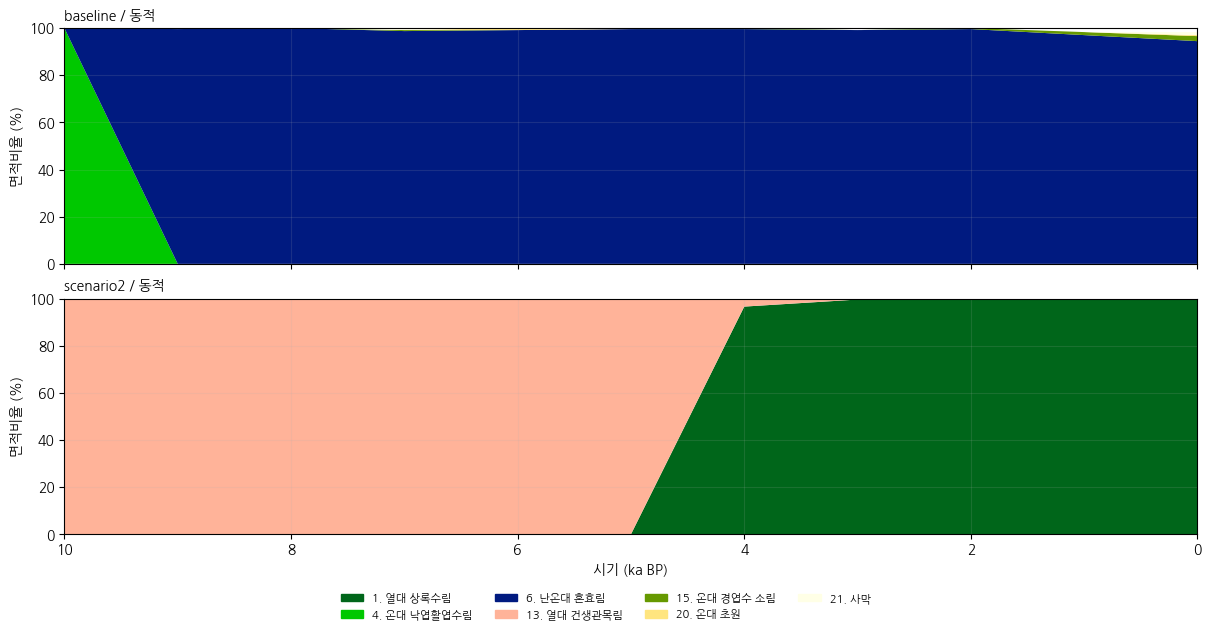

In [69]:
#@title 9. BIOME4 생물군계 면적비율
import numpy as np, pandas as pd
from IPython.display import display
report_dir=comparison_report

if "biome4_full_id_counts" not in scenario_timeseries.columns:
    raise RuntimeError("BIOME4 생물군계 집계가 없습니다.")

def parse_biome_counts(value):
    counts={code:0 for code in BIOME4_NAMES}
    for token in str(value).split(";"):
        if ":" in token:
            code,count=token.strip().split(":",1)
            code=int(code)
            if code in counts:
                counts[code]+=int(float(count))
    return counts

records=[]
for row in scenario_timeseries.itertuples(index=False):
    counts=parse_biome_counts(row.biome4_full_id_counts)
    for code,num in counts.items():
        records.append({
            "scenario":row.scenario,"model":row.model,
            "ka_bp":float(row.ka_bp),"biome_id":code,
            "biome_name":BIOME4_NAMES[code],
            "biome_name_ko":BIOME4_NAMES_KO[code],
            "biome_description_ko":BIOME4_DESCRIPTIONS_KO[code],
            "biome_example_ko":BIOME4_EXAMPLES_KO[code],
            "biome_example_source":BIOME4_EXAMPLE_SOURCE[code],
            "cells":num,
            "area_percent":100.0*num/int(row.n_cells)
        })

biome_ratios=pd.DataFrame(records)
biome_ratios.to_csv(report_dir/"biome4_biome_ratio_all_times.csv",index=False,encoding="utf-8-sig")

# 시나리오별 BIOME4 생물군계 면적비율 시계열
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

present_ids=sorted(
    biome_ratios.loc[biome_ratios.cells>0,"biome_id"].unique().astype(int)
)
fig,axes=plt.subplots(
    len(scenario_configs),1,
    figsize=(12,max(3.2,3.1*len(scenario_configs))),
    sharex=True,squeeze=False,constrained_layout=True
)
for ax,sc in zip(axes[:,0],scenario_configs):
    sub=biome_ratios[
        (biome_ratios.scenario==sc["name"]) &
        (biome_ratios.model==sc["model"])
    ]
    wide=sub.pivot(index="ka_bp",columns="biome_id",values="area_percent")
    wide=wide.reindex(columns=present_ids,fill_value=0).sort_index(ascending=False).fillna(0)
    ax.stackplot(
        wide.index.to_numpy(float),
        *[wide[k].to_numpy(float) for k in present_ids],
        colors=[BIOME4_COLORS[k] for k in present_ids],
        linewidth=0
    )
    ax.set_xlim(start_ka,end_ka)
    ax.set_ylim(0,100)
    ax.set_ylabel("면적비율 (%)")
    ax.set_title(f'{sc["name"]} / {sc["model"]}',loc="left",fontsize=10)
    ax.grid(alpha=.15)
axes[-1,0].set_xlabel("시기 (ka BP)")
if present_ids:
    fig.legend(
        handles=[Patch(color=BIOME4_COLORS[k],label=f"{k}. {BIOME4_NAMES_KO[k]}")
                 for k in present_ids],
        loc="outside lower center",ncol=min(4,len(present_ids)),frameon=False,fontsize=8
    )
fig.savefig(report_dir/"biome4_area_percent_timeseries.png",dpi=180,bbox_inches="tight")
plt.show()


## 9A. BIOME4 PFT


PFT 잠재생산·LAI·제약 통과율: 5 kyr 간격


,scenario,model,ka_bp,pft_id,pft_name,potential_npp,potential_lai,constraint_pass_fraction
0,baseline,동적,10.0,1,열대 상록교목,0.0000,0.0000,0.0
1,baseline,동적,10.0,2,열대 건기낙엽교목,0.0000,0.0000,0.0
2,baseline,동적,10.0,3,온대 상록활엽교목,0.0000,0.0000,0.0
3,baseline,동적,10.0,4,온대 낙엽교목,714.9441,3.3537,1.0
4,baseline,동적,10.0,5,냉량 침엽교목,615.4336,3.4703,1.0
...,...,...,...,...,...,...,...,...
281,scenario2,동적,0.0,9,C4 열대 초본,1330.8752,6.4475,1.0
282,scenario2,동적,0.0,10,C3/C4 건조지 목본,646.6951,3.2920,1.0
283,scenario2,동적,0.0,11,툰드라 관목,0.0000,0.0000,0.0
284,scenario2,동적,0.0,12,한랭 초본,0.0000,0.0000,0.0


우점 PFT 선택 격자비율: 5 kyr 간격 (selection_source 열로 판정 근거 확인)


,scenario,model,ka_bp,pft_id,pft_name,selection_source,chosen_cells,chosen_cells_percent
0,baseline,동적,10.0,0,PFT 미선택,BIOME4 optPFT,0,0.0
1,baseline,동적,10.0,1,열대 상록교목,BIOME4 optPFT,0,0.0
2,baseline,동적,10.0,2,열대 건기낙엽교목,BIOME4 optPFT,0,0.0
3,baseline,동적,10.0,3,온대 상록활엽교목,BIOME4 optPFT,0,0.0
4,baseline,동적,10.0,4,온대 낙엽교목,BIOME4 optPFT,234,100.0
...,...,...,...,...,...,...,...,...
303,scenario2,동적,0.0,9,C4 열대 초본,BIOME4 optPFT,0,0.0
304,scenario2,동적,0.0,10,C3/C4 건조지 목본,BIOME4 optPFT,0,0.0
305,scenario2,동적,0.0,11,툰드라 관목,BIOME4 optPFT,0,0.0
306,scenario2,동적,0.0,12,한랭 초본,BIOME4 optPFT,0,0.0


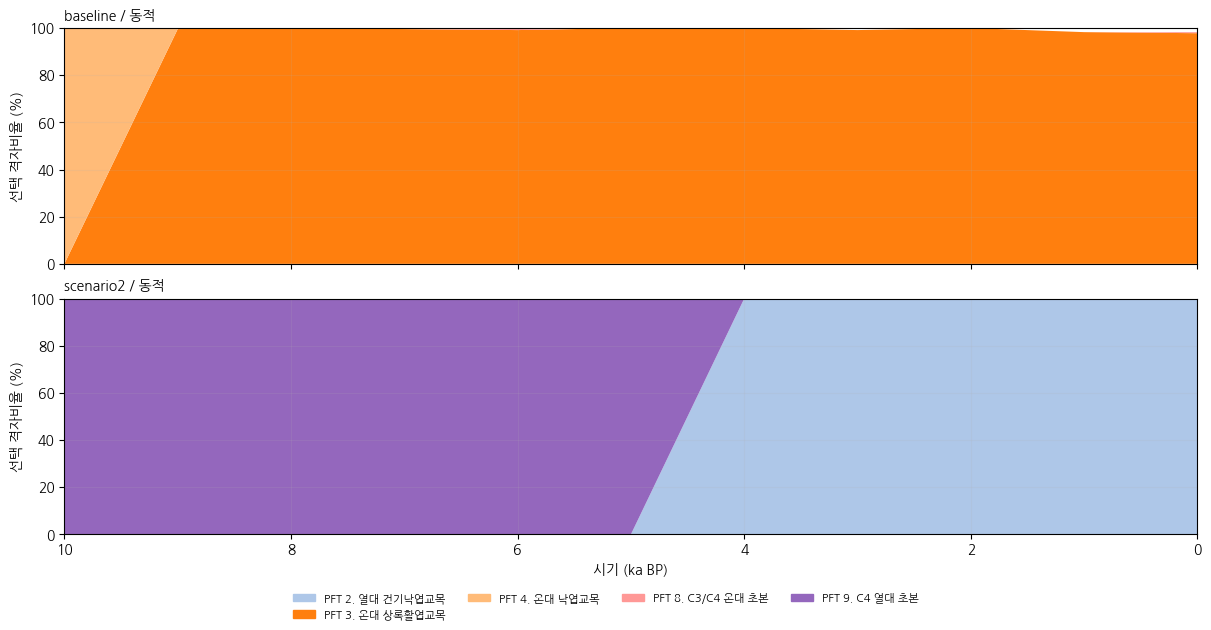

In [70]:
#@title 9A. 13개 PFT 진단표
PFT_NAMES={
    1:"열대 상록교목",2:"열대 건기낙엽교목",3:"온대 상록활엽교목",
    4:"온대 낙엽교목",5:"냉량 침엽교목",6:"아한대 상록교목",
    7:"아한대 낙엽교목",8:"C3/C4 온대 초본",9:"C4 열대 초본",
    10:"C3/C4 건조지 목본",11:"툰드라 관목",12:"한랭 초본",13:"지의류·광엽초본"
}

PFT_EXAMPLES_KO={
    1:"열대우림 상록교목(Vatica, Dipterocarpus, Pometia, Myristica 등)",
    2:"열대 계절림·건기낙엽 교목(Gironniera, Burretiodendron, Kleinhovia, Antiaris 등)",
    3:"난온대·아열대 상록활엽교목(Castanopsis, Cyclobalanopsis, Lithocarpus, 상록 Quercus 등)",
    4:"온대 낙엽교목(Quercus, Acer, Tilia, Betula 등)",
    5:"온대 상록침엽교목(Picea, Abies, Tsuga, Pinus 등)",
    6:"아한대 상록교목(Picea, Abies, Pinus 계열)",
    7:"아한대 낙엽교목(Larix, Betula, Sorbus; 지역에 따라 Populus 등)",
    8:"온대 초원·스텝의 C3/C4 초본(Stipa, Festuca 등)",
    9:"열대·아열대 초원·사바나의 C4 초본",
    10:"건조지 C3/C4 목본·관목(Atriplex, Euphorbia 등)",
    11:"툰드라 관목(Alnus, Betula, Salix, Pinus pumila 등)",
    12:"한랭 초본·사초류(Artemisia, Kobresia, Stipa, Festuca, Carex 등)",
    13:"방석형 광엽초본·지의류·선태류(Papaver, Draba, Saxifragaceae 등)"
}
PFT_EXAMPLE_SOURCE={
    1:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    2:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    3:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    4:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    5:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    6:"Bradshaw et al. (2025) PFT; Ni (2000) representative dominants",
    7:"Kaplan et al. (2002): Larix, Betula, Sorbus; Ni (2000): Larix, Betula, Populus",
    8:"Kaplan et al. (2003): temperate grass C3/C4; Ni & Herzschuh (2011): Stipa/Festuca",
    9:"Kaplan et al. (2002); Edwards et al. (2010): tropical/subtropical C4 grasses",
    10:"Kaplan et al. (2002): C4 desert shrubs including Atriplex and Euphorbia",
    11:"Kaplan et al. (2003) Table 1: Alnus, Betula, Salix, Pinus pumila",
    12:"Kaplan et al. (2003) Table 1; Ni & Herzschuh (2011) Table 2",
    13:"Kaplan et al. (2003) Table 1; Ni & Herzschuh (2011) Table 2"
}

print("BIOME4 13개 PFT와 대표 식생 예시")
print(
    "※ PFT는 종 목록이 아니라 생리·형태·생활사 특성이 유사한 식물 기능군입니다. "
    "대표 식생 예시는 이해를 돕기 위한 현실 식생 대응 예시입니다."
)
pft_reference_table=pd.DataFrame([
    {
        "PFT":pid,
        "국문명":PFT_NAMES[pid],
        "대표 식생 예시":PFT_EXAMPLES_KO[pid],
        "근거":PFT_EXAMPLE_SOURCE[pid],
    }
    for pid in range(1,14)
])
display(pft_reference_table)
pft_reference_table.to_csv(
    report_dir/"pft_reference_examples.csv",
    index=False,encoding="utf-8-sig"
)

_required_pft_cols=[]
for pid in range(1,14):
    _required_pft_cols += [
        f"pft{pid:02d}_npp_mean",
        f"pft{pid:02d}_lai_mean",
        f"pft{pid:02d}_constraint_pass_fraction",
    ]
_required_pft_cols += [f"selected_pft{pid:02d}_count" for pid in range(0,14)]
_required_pft_cols += ["pft_selection_source"]
_missing=[c for c in _required_pft_cols if c not in scenario_timeseries.columns]
if _missing:
    raise RuntimeError(
        "현재 결과는 PFT 진단 열이 없는 이전 실행 결과입니다. "
        "수정된 2번 셀을 실행한 뒤 6. 시나리오 실행부터 다시 실행하십시오. "
        f"누락 예: {_missing[:6]}"
    )

pft_rows=[]
chosen_rows=[]
for _,row in scenario_timeseries.iterrows():
    n_cells=int(row["n_cells"])
    for pid,pname in PFT_NAMES.items():
        prefix=f"pft{pid:02d}_"
        pft_rows.append({
            "scenario":row["scenario"],
            "model":row["model"],
            "ka_bp":float(row["ka_bp"]),
            "pft_id":pid,
            "pft_name":pname,
            "pft_example_ko":PFT_EXAMPLES_KO[pid],
            "pft_example_source":PFT_EXAMPLE_SOURCE[pid],
            "potential_npp":float(row[prefix+"npp_mean"]),
            "potential_lai":float(row[prefix+"lai_mean"]),
            "constraint_pass_fraction":float(row[prefix+"constraint_pass_fraction"])
        })

    counts=[int(row[f"selected_pft{pid:02d}_count"]) for pid in range(0,14)]
    total=sum(counts)
    selection_source=str(row["pft_selection_source"])
    if total<=0:
        counts=[n_cells]+[0]*13
        total=n_cells
        selection_source="선택 PFT 없음"
    for pid,num in enumerate(counts):
        chosen_rows.append({
            "scenario":row["scenario"],
            "model":row["model"],
            "ka_bp":float(row["ka_bp"]),
            "pft_id":pid,
            "pft_name":PFT_NAMES.get(pid,"PFT 미선택"),
            "pft_example_ko":PFT_EXAMPLES_KO.get(pid,""),
            "pft_example_source":PFT_EXAMPLE_SOURCE.get(pid,""),
            "selection_source":selection_source,
            "chosen_cells":num,
            "chosen_cells_percent":100.0*num/total if total else np.nan
        })

pft_long=pd.DataFrame(pft_rows)
chosen_pft=pd.DataFrame(chosen_rows)
pft_long.to_csv(report_dir/"pft_all_times.csv",index=False,encoding="utf-8-sig")
chosen_pft.to_csv(report_dir/"selected_pft_grid_ratio_all_times.csv",index=False,encoding="utf-8-sig")

# 5 kyr 간격 진단표
_pft_5k_mask=np.zeros(len(pft_long),dtype=bool)
for age in selected_ages:
    _pft_5k_mask |= np.isclose(pft_long.ka_bp.to_numpy(float),float(age),atol=1e-6)
pft_5k=pft_long.loc[_pft_5k_mask].copy()
chosen_pft_5k=chosen_pft.loc[
    np.logical_or.reduce([
        np.isclose(chosen_pft.ka_bp.to_numpy(float),float(age),atol=1e-6)
        for age in selected_ages
    ])
].copy()
pft_5k.to_csv(report_dir/"pft_5k_diagnostics.csv",index=False,encoding="utf-8-sig")
chosen_pft_5k.to_csv(report_dir/"selected_pft_5k_ratio.csv",index=False,encoding="utf-8-sig")

print("PFT 잠재생산·LAI·제약 통과율: 5 kyr 간격")
display(pft_5k.round(4))
print("우점 PFT 선택 격자비율: 5 kyr 간격 (selection_source 열로 판정 근거 확인)")
display(chosen_pft_5k.round(3))

# 시나리오별 최적 PFT 선택 격자 비율 시계열
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
pft_ids=sorted(
    chosen_pft.loc[
        (chosen_pft.pft_id>0)&(chosen_pft.chosen_cells>0),"pft_id"
    ].unique().astype(int)
)
pft_palette=plt.get_cmap("tab20")
pft_colors={pid:pft_palette((pid-1)%20) for pid in pft_ids}
fig,axes=plt.subplots(
    len(scenario_configs),1,
    figsize=(12,max(3.2,3.1*len(scenario_configs))),
    sharex=True,squeeze=False,constrained_layout=True
)
for ax,sc in zip(axes[:,0],scenario_configs):
    sub=chosen_pft[
        (chosen_pft.scenario==sc["name"]) &
        (chosen_pft.model==sc["model"])
    ]
    wide=sub.pivot(index="ka_bp",columns="pft_id",values="chosen_cells_percent")
    wide=wide.reindex(columns=pft_ids,fill_value=0).sort_index(ascending=False).fillna(0)
    ax.stackplot(
        wide.index.to_numpy(float),
        *[wide[k].to_numpy(float) for k in pft_ids],
        colors=[pft_colors[k] for k in pft_ids],
        linewidth=0
    )
    ax.set_xlim(start_ka,end_ka)
    ax.set_ylim(0,100)
    ax.set_ylabel("선택 격자비율 (%)")
    ax.set_title(f'{sc["name"]} / {sc["model"]}',loc="left",fontsize=10)
    ax.grid(alpha=.15)
axes[-1,0].set_xlabel("시기 (ka BP)")
if pft_ids:
    fig.legend(
        handles=[
            Patch(color=pft_colors[k],label=f"PFT {k}. {PFT_NAMES[k]}")
            for k in pft_ids
        ],
        loc="outside lower center",
        ncol=min(4,len(pft_ids)),frameon=False,fontsize=8
    )
fig.savefig(report_dir/"pft_selected_percent_timeseries.png",dpi=180,bbox_inches="tight")
plt.show()


## 10. 시나리오 5 kyr 간격 비교


In [71]:
#@title 10. 시나리오 설정과 5 kyr 간격 결과
settings_table=pd.DataFrame(scenario_configs)

_result_candidates=[
    "scenario","model","ka_bp",
    "mean_elevation_m","mean_soil_depth_m","mean_npp","mean_eemt",
    "mean_lai","mean_aet_mm_yr","mean_runoff_mm_yr",
    "mean_agb_proxy_kg_m2",
    "dominant_biome4_id"
]
result_columns=[c for c in _result_candidates if c in scenario_timeseries.columns]

_5k_mask=np.zeros(len(scenario_timeseries),dtype=bool)
for age in selected_ages:
    _5k_mask |= np.isclose(
        scenario_timeseries.ka_bp.to_numpy(float),
        float(age),atol=1e-6
    )

comparison_5k_table=(
    scenario_timeseries.loc[_5k_mask,result_columns]
    .sort_values(["ka_bp","scenario"],ascending=[False,True])
    .reset_index(drop=True)
)

end_table=(
    scenario_timeseries.loc[
        np.isclose(
            scenario_timeseries.ka_bp.to_numpy(float),
            float(end_ka),atol=1e-6
        ),
        result_columns
    ]
    .copy()
    .reset_index(drop=True)
)

print("시나리오 설정")
display(settings_table.round(4))
print("5 kyr 간격 결과")
display(comparison_5k_table.round(4))
print("종료시점 결과")
display(end_table.round(4))

settings_table.to_csv(
    report_dir/"scenario_settings.csv",index=False,encoding="utf-8-sig"
)
comparison_5k_table.to_csv(
    report_dir/"scenario_5k_results.csv",index=False,encoding="utf-8-sig"
)
end_table.to_csv(
    report_dir/"scenario_end_results.csv",index=False,encoding="utf-8-sig"
)


시나리오 설정


,name,model,koppen,representative_id,soil_depth_multiplier,uplift_m_per_kyr,soil_production_a,hillslope_c,hillslope_d,fluvial_K0
0,baseline,동적,Dwa,KR_SEOUL,1.0,0.08,0.037,0.033,0.05,0.02
1,scenario2,동적,Am,AMAZON_BASIN,1.0,0.08,0.037,0.033,0.05,0.02


5 kyr 간격 결과


,scenario,model,ka_bp,mean_elevation_m,mean_soil_depth_m,mean_npp,mean_eemt,mean_lai,mean_aet_mm_yr,mean_runoff_mm_yr,mean_agb_proxy_kg_m2,dominant_biome4_id
0,baseline,동적,10.0,382.5370,0.5500,715.0000,107.9079,3.3500,625.0000,899.0000,7.1500,4
1,scenario2,동적,10.0,382.5370,0.5500,806.4017,134.7423,3.4180,NaN,923.0000,8.0640,13
2,baseline,동적,5.0,383.0983,1.3262,600.7564,95.3764,3.0683,571.8291,891.6538,6.0076,6
3,scenario2,동적,5.0,383.4205,1.9356,789.3718,123.6109,3.4424,NaN,801.9915,7.8937,13
4,baseline,동적,0.0,383.3711,1.4955,735.1709,77.0237,3.2873,604.6267,548.8130,7.3517,6
5,scenario2,동적,0.0,383.8417,2.2752,1248.3333,149.2714,4.0300,979.8162,830.1581,12.4833,1


종료시점 결과


,scenario,model,ka_bp,mean_elevation_m,mean_soil_depth_m,mean_npp,mean_eemt,mean_lai,mean_aet_mm_yr,mean_runoff_mm_yr,mean_agb_proxy_kg_m2,dominant_biome4_id
0,baseline,동적,0.0,383.3711,1.4955,735.1709,77.0237,3.2873,604.6267,548.8130,7.3517,6
1,scenario2,동적,0.0,383.8417,2.2752,1248.3333,149.2714,4.0300,979.8162,830.1581,12.4833,1


## 11. 보고서 파일


In [ ]:
#@title 11. 전체 실험 보고서 자료 압축
download_report_zip = False #@param {type:"boolean"}
from zipfile import ZipFile,ZIP_DEFLATED
from pathlib import Path

template_path=comparison_report/"student_report_template.md"
template_text=f"""# 생태환경과 지리: 실습 4 경관진화모델링 — 전 세계 기후대·가상유역 보고서

## 1. 실험 목적
- 시나리오 수: {scenario_count}

## 2. 시나리오 설정
- 표: scenario_settings.csv
- 계산기간: {start_ka:g}–{end_ka:g} ka BP
- 시나리오별 모델 유형과 설정값:

## 3. 시계열 비교
- 표: all_scenarios_timeseries.csv
- 시나리오별 토심·고도·NPP 변화:

## 4. BIOME4 biome 및 PFT
- 표: biome4_biome_ratio_all_times.csv
- 참고표: biome4_reference_examples.csv
- 표: pft_all_times.csv
- 표: selected_pft_grid_ratio_all_times.csv
- 참고표: pft_reference_examples.csv
- 출처표: vegetation_example_sources.csv
- BIOME4 biome과 최적 PFT의 변화:

## 5. 5 kyr 간격 및 종료시점 비교
- 표: scenario_5k_results.csv
- 표: scenario_end_results.csv
- 시나리오별 결과 비교:

## 6. 토의
- 기후·식생·토심·사면과정의 상호작용:
- 시나리오에서 변경한 조건과 유지한 조건:
- 모형 결과 해석의 한계:

## 재현성
- PB4Studio BIOME4–Pelletier / Beyer climate data
- 모델 SHA256: {checksum}
- 원본: https://github.com/physical-geogrpahy-forever/yongneup_nb
"""
template_path.write_text(template_text,encoding="utf-8")


# 결과 엑셀 및 변수 설명
import re
import pandas as pd

variable_defs={
    "scenario":("시나리오","시나리오 이름",""),
    "model":("모델 유형","정적 또는 동적 모델",""),
    "scenario_number":("시나리오 번호","설정한 시나리오의 순서",""),
    "scenario_count":("시나리오 수","전체 시나리오 개수","개"),
    "target_basin_area_km2":("목표 유역면적","가상유역 생성 시 사용자가 지정한 목표 면적","km²"),
    "actual_basin_area_km2":("실제 유역면적","불규칙 유역 마스크로 생성된 실제 면적","km²"),
    "grid_size":("격자 배열 크기","정사각형 계산영역의 한 변 격자 수","개"),
    "cell_size_m":("격자 해상도","격자 한 변의 길이","m"),
    "bounding_box_width_m":("경계상자 폭","가상유역 계산영역의 한 변 길이","m"),
    "valid_cell_count":("유역 내부 격자 수","유역 마스크 내부의 유효 격자 수","개"),
    "basin_area_m2":("실제 유역면적","유효 격자 수와 해상도로 계산한 유역면적","m²"),
    "name":("시나리오 이름","시나리오를 구별하는 이름",""),
    "koppen":("쾨펜 기후형","현재 기준 쾨펜 기후형 코드",""),
    "representative_id":("기후 대표지점 ID","기후 대표지점 식별자",""),
    "대표 지역":("기후 대표 지역","선택한 기후 대표지점의 도시 또는 지리적 지역명",""),
    "대표지점 표시":("기후 대표지점 표시","지역명·좌표·대표지점 ID를 결합한 표시문자열",""),
    "soil_depth_multiplier":("초기 토심 배율","초기 토심 자료에 적용한 배율","배"),
    "uplift_m_per_kyr":("융기율","천 년당 지표 융기량","m/kyr"),
    "soil_production_a":("토양생산 계수 a","EEMT 기반 토양생산식의 계수 a",""),
    "hillslope_c":("사면수송 계수 c","EEMT에 대응하는 사면수송식의 계수 c",""),
    "hillslope_d":("사면수송 계수 d","지상부 바이오매스에 대응하는 사면수송식의 계수 d",""),
    "fluvial_K0":("유수침식 계수 K0","유수침식 계산에 사용하는 기준 계수",""),
    "mean_temp_C":("연평균 기온","12개월 평균기온의 산술평균","°C"),
    "annual_precip_mm":("연강수량","12개월 월강수량의 합","mm/yr"),
    "mean_cloud_pct":("연평균 운량","월평균 운량의 연평균","%"),
    "ka_bp":("현재 이전 시기","현재를 기준으로 한 과거 시점","ka BP"),
    "resolution_m":("격자 해상도","공간격자의 한 변 길이","m"),
    "n_cells":("유효 격자 수","모의에 포함된 유효 격자의 개수","개"),
    "area_m2":("유효 면적","유효 격자의 총면적","m²"),
    "relief_m":("기복량","최고 고도와 최저 고도의 차이","m"),
    "dominant_vegetation_code":("우점 식생 코드","PB4Studio 내부 집계에 사용된 우점 식생 코드",""),
    "dominant_biome4_id":("우점 BIOME4 생물군계","BIOME4 원본 생물군계의 최빈 ID",""),
    "biome4_full_id_counts":("BIOME4 생물군계별 격자 수","생물군계 ID와 격자 수를 콜론 및 세미콜론으로 구분한 값",""),
    "vegetation_class_richness":("식생 유형 수","모의 영역에 나타난 식생 유형의 개수","개"),
    "vegetation_min_code":("최소 식생 코드","PB4Studio 내부 식생 코드의 최솟값",""),
    "vegetation_max_code":("최대 식생 코드","PB4Studio 내부 식생 코드의 최댓값",""),
    "vegetation_class_counts":("식생 유형별 격자 수","PB4Studio 내부 식생 유형의 격자 수 집계",""),
    "vegetation_nonvegetated_cell_count":("비식생 격자 수","내부 식생 분류상 비식생에 해당하는 격자 수","개"),
    "vegetation_unclassified_cell_count":("미분류 격자 수","식생 유형이 판정되지 않은 격자 수","개"),
    "vegetation_unclassified_fraction":("미분류 격자 비율","유효 격자 중 식생 미분류 비중","비율"),
    "case_label":("실행 구분","모델 실행의 내부 구분",""),
    "biome_id":("BIOME4 생물군계 ID","BIOME4 생물군계 분류 코드(1–28)",""),
    "biome_name":("생물군계 영문명","BIOME4 생물군계의 영문 명칭",""),
    "biome_name_ko":("생물군계 국문명","BIOME4 생물군계의 국문 명칭",""),
    "biome_description_ko":("생물군계 설명","생물군계의 생태적 특성에 관한 국문 설명",""),
    "biome_example_ko":("생물군계 대표 식생 예시","해당 BIOME4 생물군계에 대응하는 현실 식생의 교육용 예시",""),
    "biome_example_source":("생물군계 예시 근거","대표 식생 예시를 확인한 문헌",""),
    "pft_example_ko":("PFT 대표 식생 예시","해당 PFT에 대응하는 현실 식생·분류군의 교육용 예시",""),
    "pft_example_source":("PFT 예시 근거","대표 식생 예시를 확인한 문헌",""),
    "cells":("생물군계 격자 수","해당 생물군계가 나타난 격자의 개수","개"),
    "area_percent":("생물군계 면적비율","유효 격자에서 해당 생물군계가 차지하는 면적비율","%"),
    "pft_id":("식물기능유형 ID","BIOME4 식물기능유형(PFT) 번호",""),
    "pft_name":("식물기능유형명","해당 식물기능유형의 국문 명칭",""),
    "potential_npp":("잠재 순일차생산량","해당 PFT의 잠재 순일차생산량","gC m⁻² yr⁻¹"),
    "potential_lai":("잠재 엽면적지수","해당 PFT의 잠재 엽면적지수","m²/m²"),
    "constraint_pass_fraction":("생물기후 제약 통과 비율","해당 PFT가 생물기후적 제약조건을 만족한 격자 비율","비율"),
    "chosen_cells":("선택 격자 수","해당 PFT가 최적으로 선택된 격자의 수","개"),
    "selection_source":("PFT 선택 근거","BIOME4 optPFT 또는 잠재 NPP 최대값 진단 중 사용된 기준",""),
    "chosen_cells_percent":("선택 격자 비율","해당 PFT가 우점 PFT로 선택된 격자의 비율","%"),
    "mean_agb_proxy_kg_m2":("평균 지상부 바이오매스 지표","Pelletier 결합에 사용되는 NPP 기반 지상부 바이오매스 지표의 공간평균","kg/m²"),
    "mean_lai":("평균 엽면적지수","유효 격자의 평균 LAI","m²/m²"),
    "mean_aet_mm_yr":("평균 실제증발산량","연간 실제증발산량의 공간평균","mm/yr"),
    "mean_runoff_mm_yr":("평균 유출량","연간 지표 유출량의 공간평균","mm/yr"),
}
physical={
    "elevation_m":("고도","m"),
    "soil_depth_m":("토심","m"),
    "slope":("경사도",""),
    "npp":("순일차생산량","gC m⁻² yr⁻¹"),
    "eemt":("유효 에너지 및 물질 전달량","MJ m⁻² yr⁻¹"),
    "lai":("엽면적지수","m²/m²"),
    "agb":("지상부 바이오매스","kg/m²"),
}
for key,(ko,unit) in physical.items():
    for prefix,stat in (
        ("mean_", "평균"),("sd_","표준편차"),
        ("min_","최솟값"),("max_","최댓값")
    ):
        variable_defs[prefix+key]=(stat+" "+ko,ko+"의 공간 "+stat,unit)
    variable_defs[key+"_mean_sd"]=(ko+" 평균 ± 표준편차",ko+"의 공간평균 및 표준편차를 함께 표시한 문자열",unit)

def describe_variable(col):
    if col in variable_defs:
        return variable_defs[col]
    m=re.fullmatch(r"pft(\d{2})_(npp_mean|lai_mean|constraint_pass_fraction)",col)
    if m:
        pid=int(m.group(1))
        part=m.group(2)
        ko={"npp_mean":"잠재 순일차생산량 평균",
            "lai_mean":"잠재 엽면적지수 평균",
            "constraint_pass_fraction":"생물기후 제약 통과 비율"}[part]
        unit={"npp_mean":"gC m⁻² yr⁻¹","lai_mean":"m²/m²",
              "constraint_pass_fraction":"비율"}[part]
        return (f"PFT {pid} {ko}",f"식물기능유형 {pid} ({PFT_NAMES.get(pid,'')})의 {ko}",unit)
    m=re.fullmatch(r"selected_pft(\d{2})_count",col)
    if m:
        pid=int(m.group(1))
        return (f"PFT {pid} 선택 격자 수",f"BIOME4 optPFT 또는 진단용 잠재 NPP 최대값 기준으로 PFT {pid}가 선택된 격자 수","개")
    if col.startswith("geomorph_"):
        gloss={
            "accepted_substeps_to_next":("허용된 계산 소단계 수","개"),
            "rejected_substeps_to_next":("기각된 계산 소단계 수","개"),
            "rejected_fluvial_trials_to_next":("기각된 유수침식 계산 횟수","회"),
            "min_dt_kyr_to_next":("최소 내부 시간간격","kyr"),
            "max_dt_kyr_to_next":("최대 내부 시간간격","kyr"),
            "fluvial_tolerance_m":("유수침식 허용오차","m"),
            "max_accepted_fluvial_change_m_to_next":("최대 허용 유수침식 고도변화","m"),
        }
        suffix=col[len("geomorph_"):]
        if suffix in gloss:
            ko,unit=gloss[suffix]
            return (ko,"지형발달 계산 중 "+ko,unit)
    if col.startswith("reich_lai_sapwood_"):
        return ("Reich LAI–변재목 산정값","지상부 바이오매스 산정 과정에서 기록된 "+col,"")
    return ("변수 정의 확인 필요","원본 모델 출력 변수: "+col,"")

export_tables={
    "가상유역 설정":virtual_basin_table,
    "시나리오 설정":settings_table,
    "생물군계 참고표":biome_reference_table,
    "PFT 참고표":pft_reference_table,
    "식생 예시 출처":vegetation_source_table,
    "5천년 간격":comparison_5k_table,
    "종료시점":end_table,
    "시계열":scenario_timeseries,
    "생물군계 비율":biome_ratios,
    "PFT 잠재생산":pft_long,
    "PFT 선택비율":chosen_pft,
    "PFT 5천년 진단":pft_5k,
    "PFT 5천년 선택":chosen_pft_5k,
    "연간 기후":scenario_climate_annual,
}
dictionary_rows=[]
for sheet,frame in export_tables.items():
    for column in frame.columns:
        ko,meaning,unit=describe_variable(str(column))
        dictionary_rows.append({
            "자료 시트":sheet,
            "변수명":str(column),
            "국문명":ko,
            "국문 설명":meaning,
            "단위":unit
        })
variable_dictionary=pd.DataFrame(dictionary_rows)
xlsx_path=comparison_report/"global_climate_scenario_results.xlsx"
with pd.ExcelWriter(xlsx_path,engine="xlsxwriter") as writer:
    variable_dictionary.to_excel(writer,sheet_name="변수 설명",index=False)
    for sheet,frame in export_tables.items():
        frame.to_excel(writer,sheet_name=sheet,index=False)
    for sheet in ["변수 설명",*export_tables]:
        worksheet=writer.sheets[sheet]
        worksheet.freeze_panes(1,0)
        worksheet.autofilter(0,0,
            (len(variable_dictionary) if sheet=="변수 설명" else len(export_tables[sheet])),
            (len(variable_dictionary.columns) if sheet=="변수 설명" else len(export_tables[sheet].columns))-1
        )
        if sheet=="변수 설명":
            worksheet.set_column(0,0,19)
            worksheet.set_column(1,1,37)
            worksheet.set_column(2,2,34)
            worksheet.set_column(3,3,75)
            worksheet.set_column(4,4,20)
        else:
            worksheet.set_column(0,0,19)
            worksheet.set_column(1,min(24,len(export_tables[sheet].columns)-1),17)
print("결과 엑셀:",xlsx_path)

export_zip=exp_root/"global_climate_virtual_basin_lab_report.zip"
with ZipFile(export_zip,"w",ZIP_DEFLATED) as archive:
    for file in sorted(comparison_report.rglob("*")):
        if file.is_file() and file.suffix.lower() in (".csv",".png",".md",".json",".xlsx"):
            archive.write(
                file,
                Path("comparison_report")/file.relative_to(comparison_report)
            )
    climate_summary=exp_root/"climate_forcing_annual.csv"
    if climate_summary.is_file():
        archive.write(climate_summary,"climate_forcing_annual.csv")
    if registry_path.is_file():
        archive.write(registry_path,"scenario_registry.json")
    for sc in scenario_configs:
        inputs=scenario_paths[sc["name"]]["inputs"]
        for p in sorted(inputs.glob("*")):
            if p.is_file() and p.suffix.lower() in (".csv",".geojson",".tif"):
                archive.write(p,Path(sc["name"])/"inputs"/p.name)
        w=scenario_paths[sc["name"]]["work"]
        for fn in ("teaching_settings.json","run_config.json"):
            p=w/fn
            if p.is_file():
                archive.write(p,Path(sc["name"])/fn)

print("보고서 자료 ZIP:",export_zip)
if download_report_zip:
    try:
        from google.colab import files
        files.download(str(export_zip))
    except ImportError:
        from IPython.display import FileLink
        display(FileLink(str(export_zip)))
else:
    print("내려받으려면 download_report_zip에 체크하고 이 셀을 다시 실행합니다.")
